In [1]:
import os
from openai import OpenAI
from dotenv import load_dotenv
load_dotenv()

True

## GPT-5

In [7]:

api_key = os.getenv("OPENAI_API_KEY")

client = OpenAI(api_key=api_key)

response = client.responses.create(
    model="gpt-5",
    input="Write a one-sentence bedtime story about a unicorn."
)

print(response.output_text)

Under a quilt of starlight, a gentle unicorn wandered the moonlit meadow, catching fallen wishes on her silver horn and breathing them into sweet dreams for every sleeping child.


In [ ]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import Video, display
import numpy as np
import os
import base64

In [ ]:
# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

img_path = '../data/videoframes/P1S1/frame_000032.jpg'
image_messages = [{"type": "input_image", "image_url": f"data:image/jpeg;base64,{encode_image(img_path)}", "detail": "high"}]

[{'type': 'input_text',
  'text': "This is a pedestrian's first-person view image. Describe his/her interaction with the two automated shuttles in the scene, both laterally and horizontally. Focus on the spatial relationship and movement dynamics between the pedestrian and the shuttles."},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'high'}]
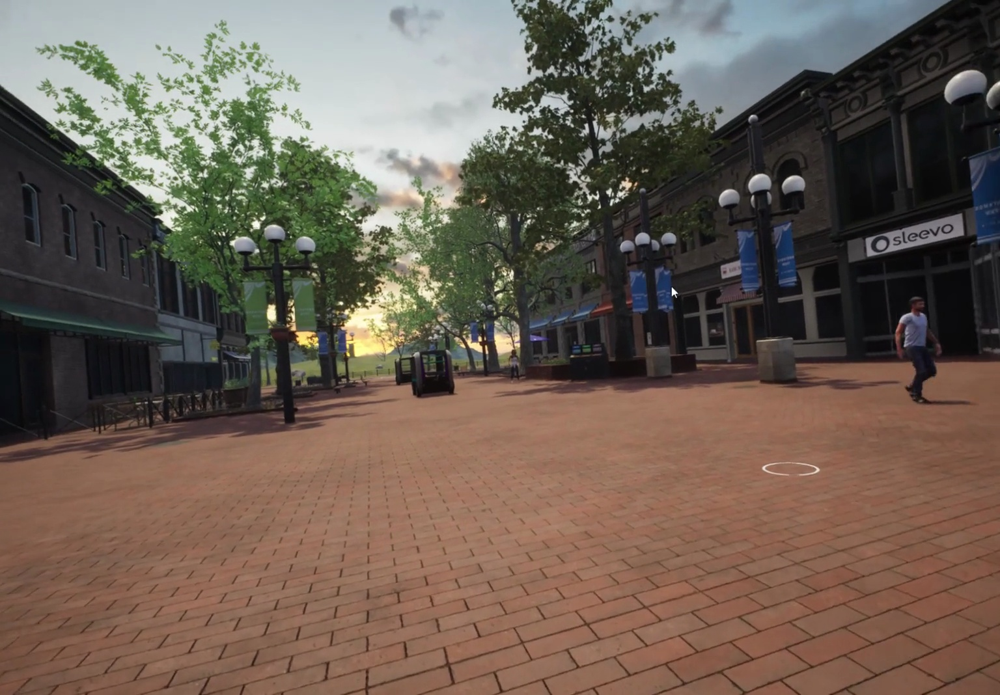

In [36]:
content = [
    {
        "type": "input_text",
        "text": "This is a pedestrian's first-person view image. Describe his/her interaction with the two automated shuttles in the scene, both laterally and horizontally. Focus on the spatial relationship and movement dynamics between the pedestrian and the shuttles.",
    }
]
content.extend(image_messages)

content

In [13]:
from openai import OpenAI
client = OpenAI()

In [37]:
%%time
response = client.responses.create(
    model="gpt-5",
    input=[
        {
            "role": "user",
            "content": content,
        }
    ]
)

CPU times: user 14.8 ms, sys: 22.6 ms, total: 37.4 ms
Wall time: 30 s


In [38]:
print(response.output_text)

- Lateral relationship: From the pedestrian’s viewpoint, both automated shuttles are traveling along the center of the brick corridor. The pedestrian is offset to the right side of their path, leaving a clear side buffer; no lateral crossing or merge is occurring.

- Horizontal relationship and motion: Both shuttles are ahead of the pedestrian. The nearer shuttle is mid‑distance in front, with a second shuttle farther ahead in the same lane. They are moving away from the pedestrian in the same direction, so the longitudinal gap to the nearer shuttle—and even more so to the farther one—is increasing. No conflict is developing; the pedestrian would simply follow behind them if continuing forward.


In [51]:
# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

img_path = '../data/videoframes/P1S3/frame_000193.jpg'
image_messages = [{"type": "input_image", "image_url": f"data:image/jpeg;base64,{encode_image(img_path)}", "detail": "high"}]

[{'type': 'input_text',
  'text': 'What could the red pedestrian signal on the pod mean?'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'high'}]
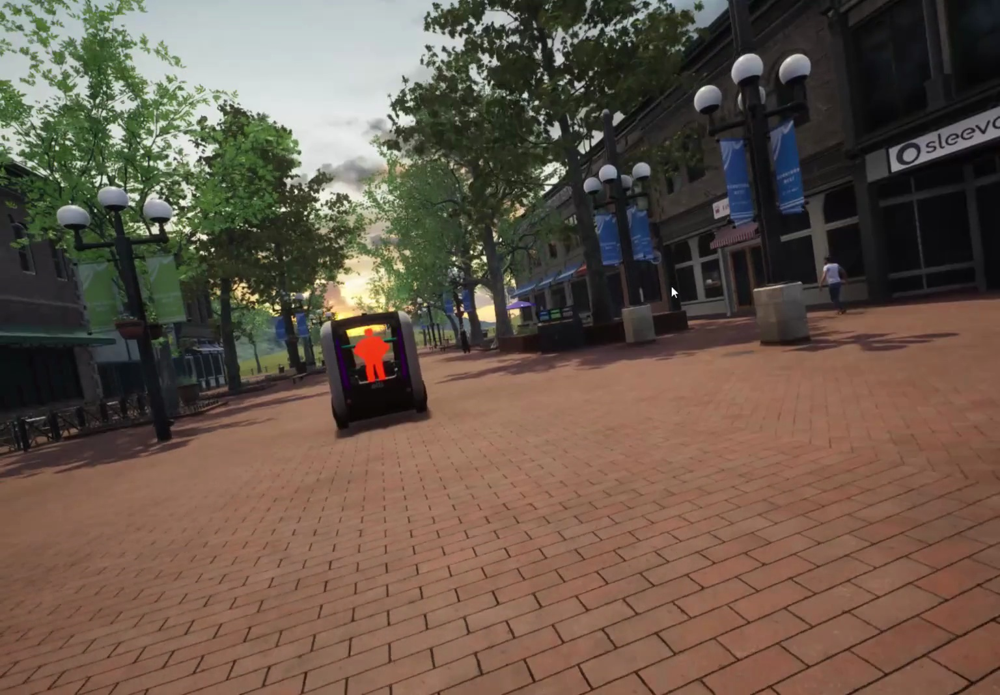

In [55]:
content = [
    {
        "type": "input_text",
        "text": "What could the red pedestrian signal on the pod mean?",
    }
]
content.extend(image_messages)

content

In [56]:
%%time
response = client.responses.create(
    model="gpt-5",
    input=[
        {
            "role": "user",
            "content": content,
        }
    ]
)

CPU times: user 14.7 ms, sys: 16 ms, total: 30.7 ms
Wall time: 8.45 s


In [57]:
print(response.output_text)

It’s a “don’t walk” message—telling pedestrians not to cross in front of the pod (not safe/it isn’t yielding).


#### Initial check on videos

In [16]:
# Get fps and basic info
video_path = '../data/videos/P4-2.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
cap.release()

FPS=36.151598492985904, frames=1123, duration(s)=31.06


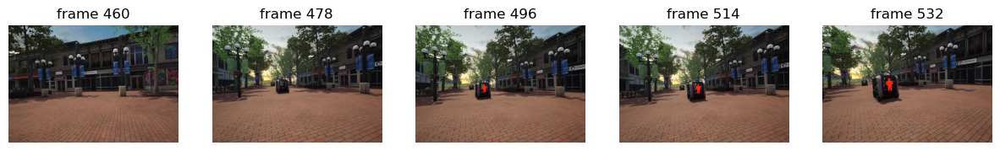

In [31]:
# Sample and show/save frames evenly across the video
def sample_frames(path, idxs, out_dir=None):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        print('Cannot open', path)
        return []
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0:
        cap.release()
        print('Video has 0 frames')
        return []
    # idxs = np.linspace(0, max(0, total-1), n_samples, dtype=int)
    # idxs = np.arange(n_samples)
    frames = []
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ret, frame = cap.read()
        if not ret:
            continue
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append((int(i), rgb))
        if out_dir:
            fname = os.path.join(out_dir, f'frame_{i:06d}.jpg')
            cv2.imwrite(fname, frame)
    cap.release()
    return frames

# show sampled frames
base_id = 460
list_idxs = [base_id, base_id+18, base_id+36, base_id+54, base_id+72]
sampled = sample_frames('../data/videos/P4-2.mp4', idxs=list_idxs, out_dir='../data/frames/P4-2')
if sampled:
    fig, axs = plt.subplots(1, len(sampled), figsize=(15, 5))
    for ax, (i, fr) in zip(axs, sampled):
        ax.imshow(fr)
        ax.set_title(f'frame {i}')
        ax.axis('off')
    plt.show()
else:
    print('No frames sampled')

In [47]:
import base64

# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

images = [
    {"path": "../data/frames/P4-2/frame_000460.jpg", "time elapsed": "0.0"},
    {"path": "../data/frames/P4-2/frame_000478.jpg", "time elapsed": "0.5"},
    {"path": "../data/frames/P4-2/frame_000496.jpg", "time elapsed": "1.0"},
    {"path": "../data/frames/P4-2/frame_000514.jpg", "time elapsed": "1.5"},
    {"path": "../data/frames/P4-2/frame_000532.jpg", "time elapsed": "2.0"},
]

image_messages = []
for img in images:
    image_messages.append({"type": "input_text", "text": f"Image at {img['time elapsed']} seconds."})
    image_messages.append({"type": "input_image", "image_url": f"data:image/jpeg;base64,{encode_image(img['path'])}", "detail": "low"})

[{'type': 'input_text', 'text': 'Image at 0.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 0.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 1.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 1.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 2.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'}]
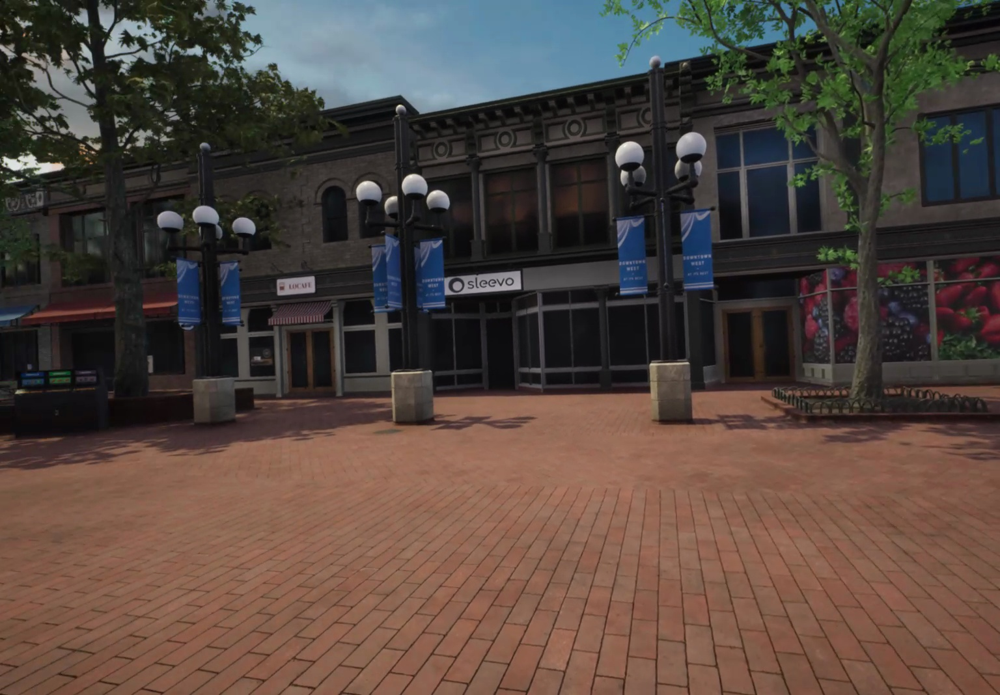
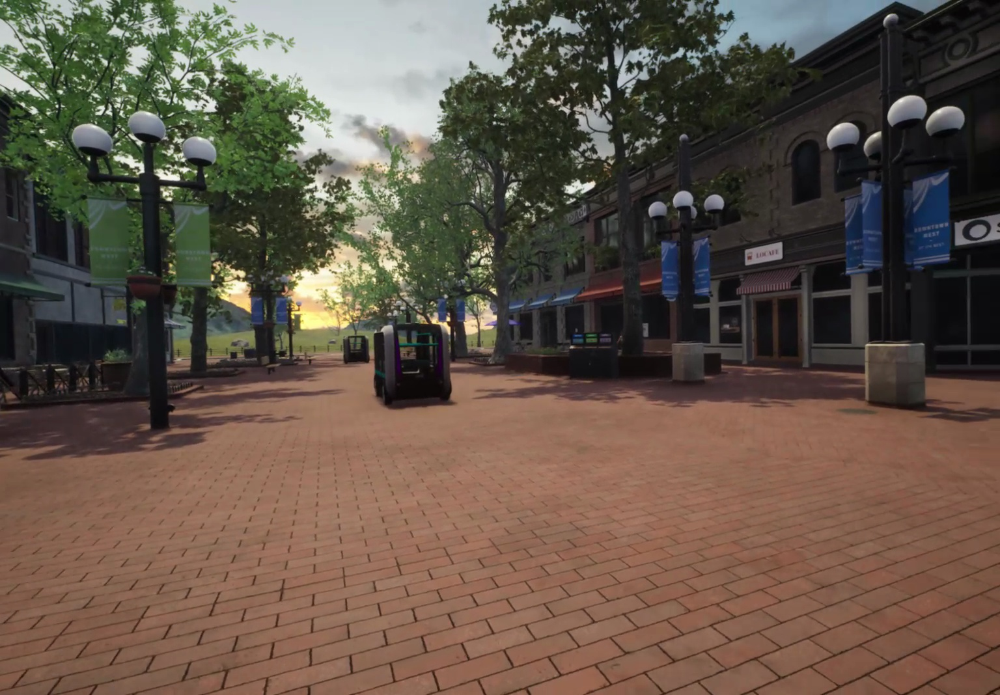
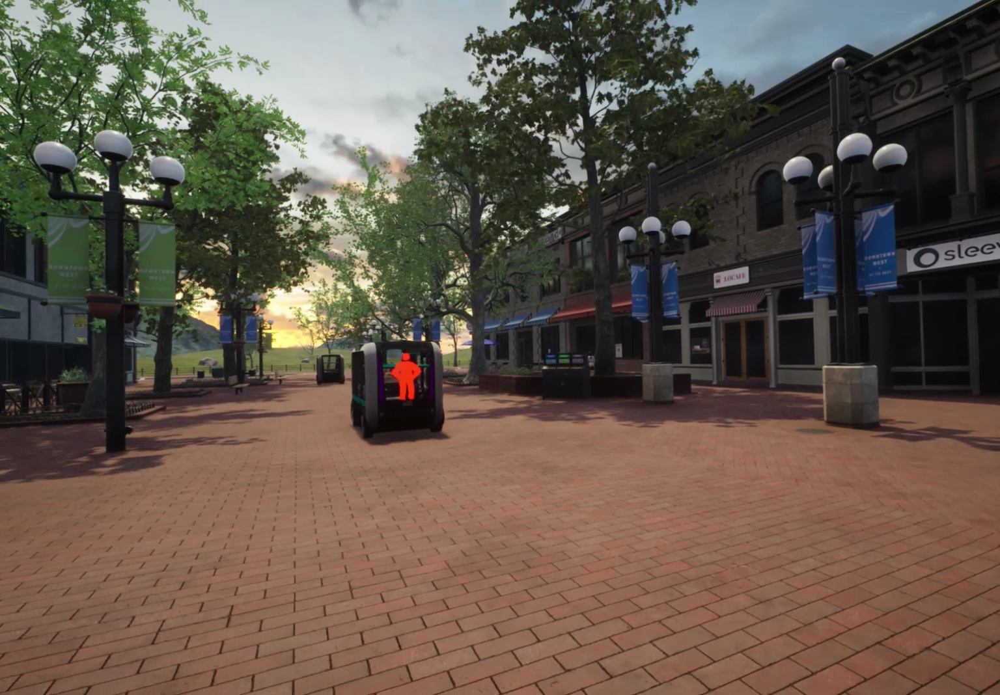
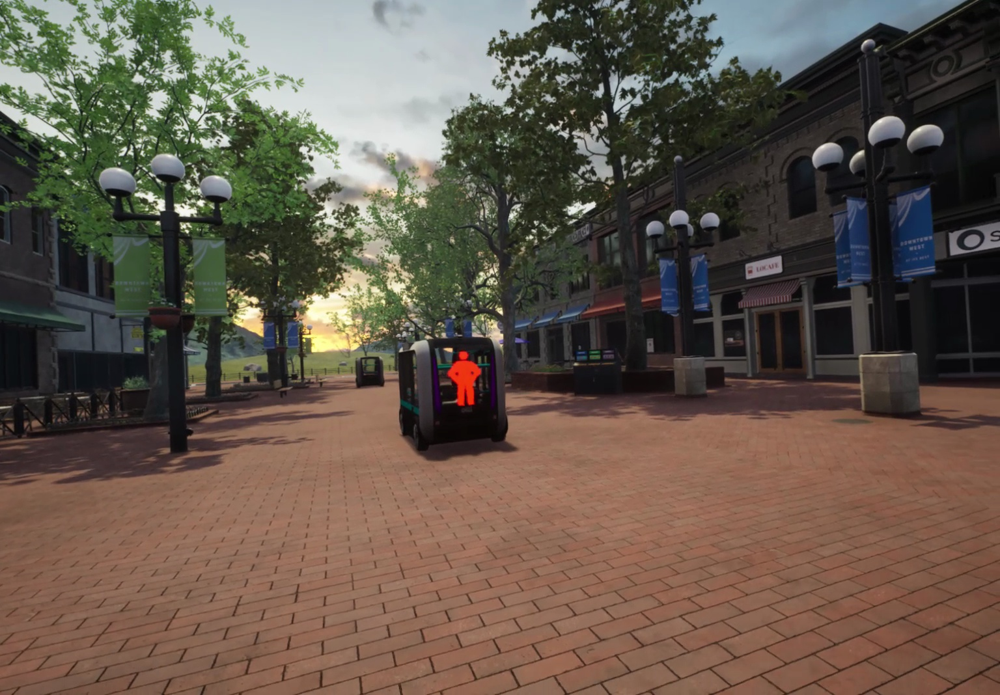
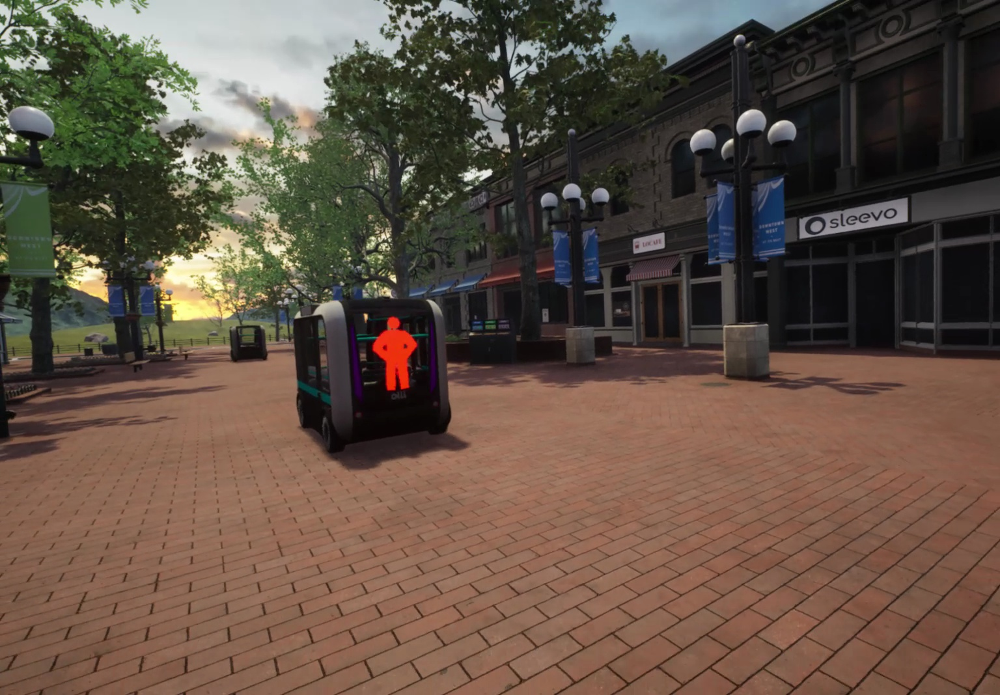

In [48]:
image_messages

[{'type': 'input_text',
  'text': 'These are frames sampled from a first-person video of an person interacting with automated vehicles in shared spaces.             Observe what the person is paying attention to. Analyze the images and provide insights about the interactions, behaviors, and any notable observations regarding safety, communication, and navigation.             Does this person intend to cross in front of the AV in the next 1.5 seconds?'},
 {'type': 'input_text', 'text': 'Image at 0.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 0.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 1.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 1.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 2.0 seconds.
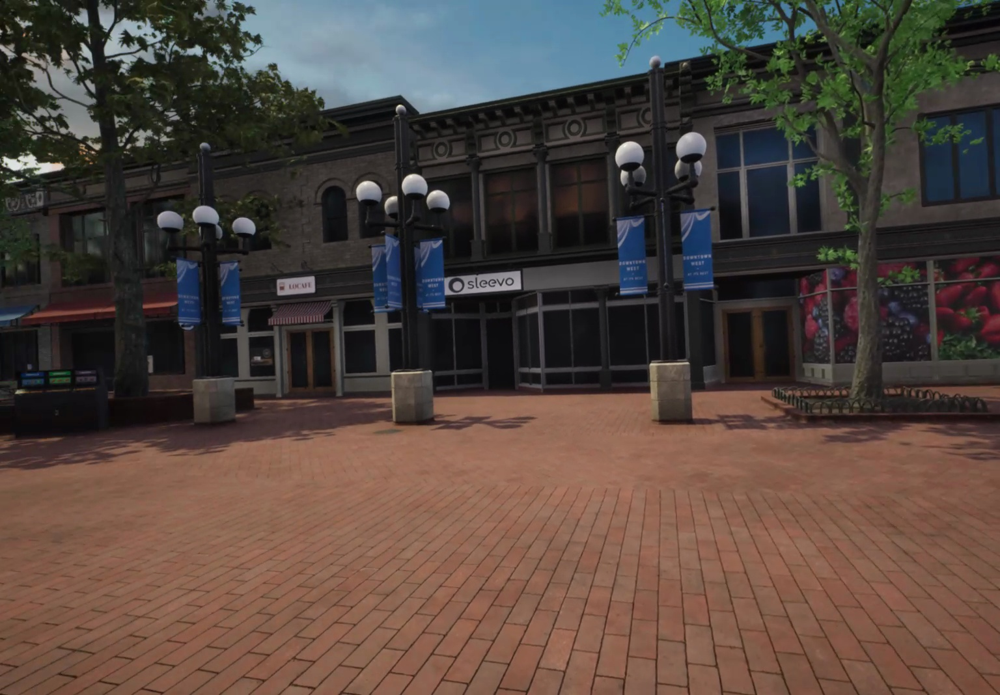
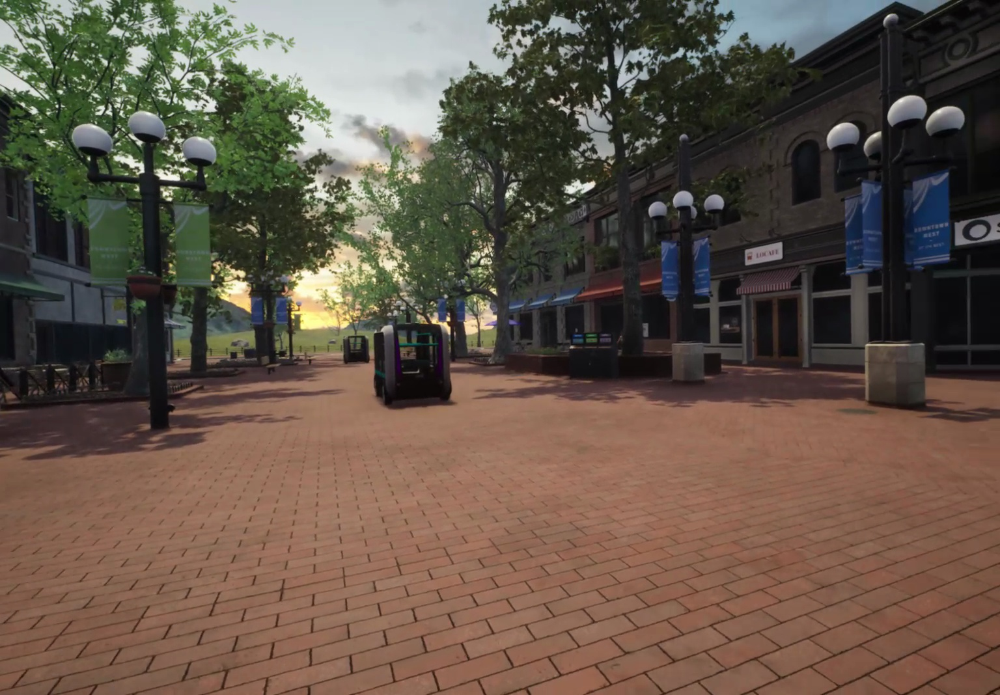
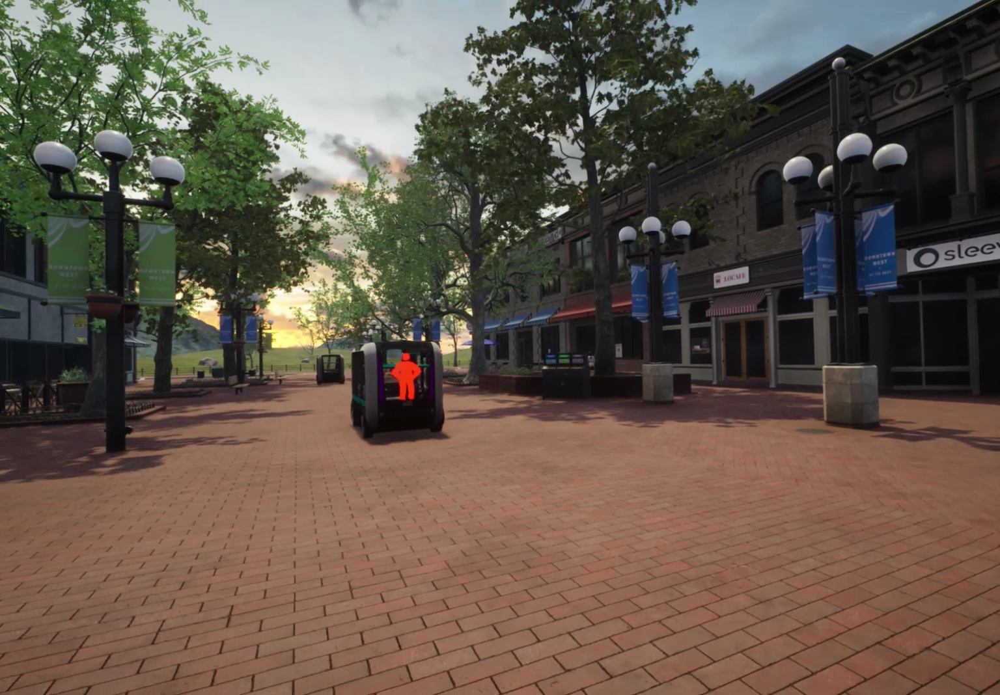
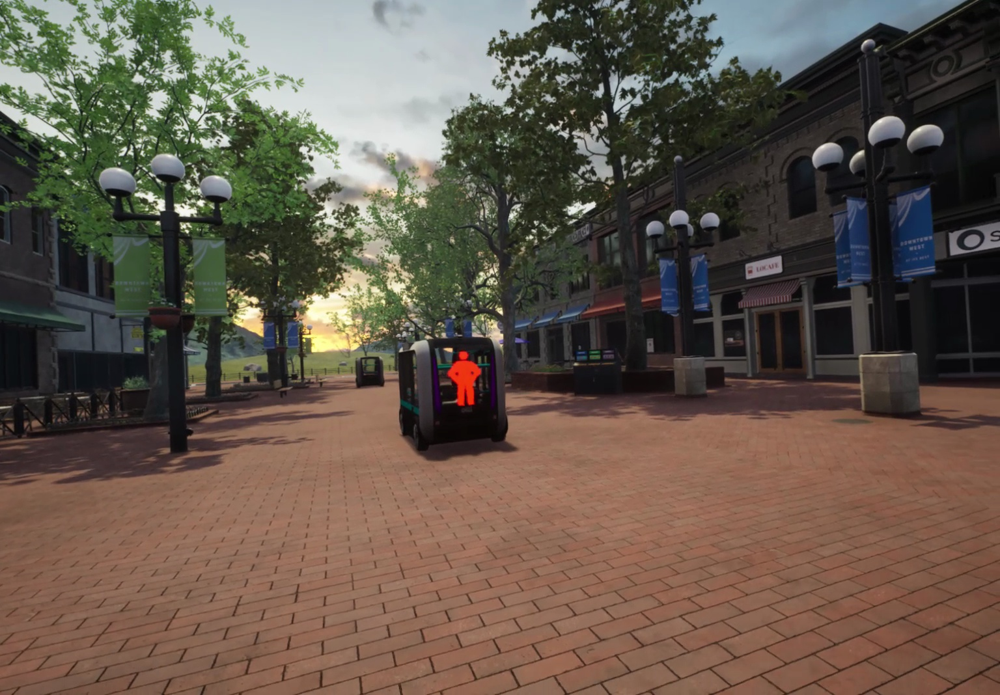
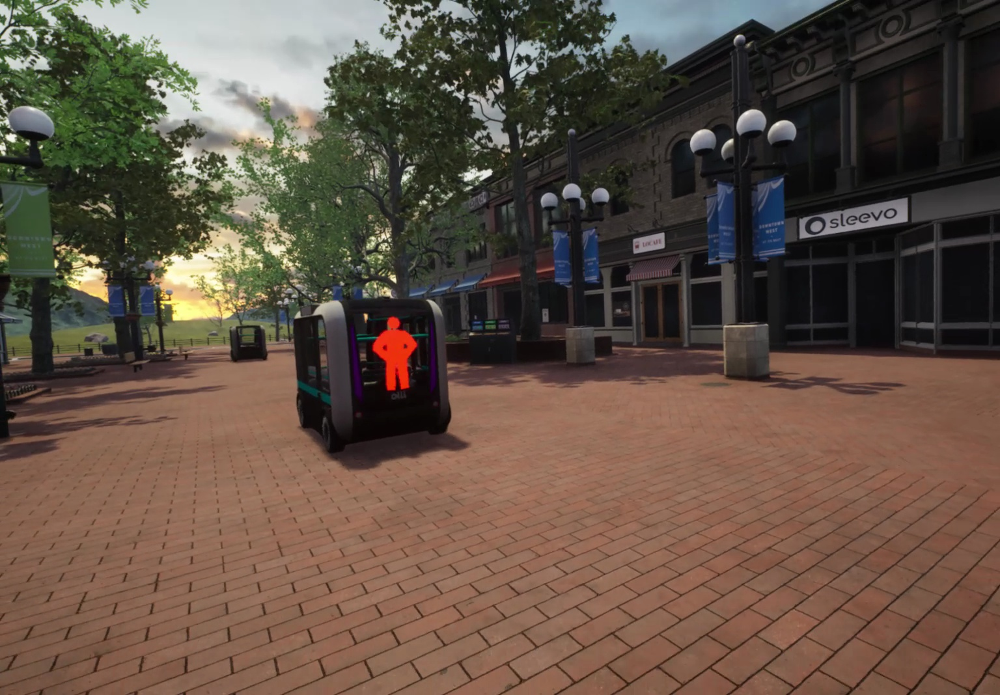

In [49]:
content = [
    {
        "type": "input_text",
        "text": "These are frames sampled from a first-person video of an person interacting with automated vehicles in shared spaces. \
            Observe what the person is paying attention to. Analyze the images and provide insights about the interactions, behaviors, and any notable observations regarding safety, communication, and navigation. \
            Does this person intend to cross in front of the AV in the next 1.5 seconds?",
    }
]
content.extend(image_messages)

content

In [50]:
from openai import OpenAI
client = OpenAI()

response = client.responses.create(
    model="gpt-5",
    input=[
        {
            "role": "user",
            "content": content,
        }
    ]
)

print(response.output_text)

Insights
- Attention: The camera (person) quickly locks onto the nearer automated pod and keeps it centered, watching its approach and front display.
- Communication: The AV’s eHMI shows a red standing human symbol, which generally communicates “do not cross / wait.” The person appears to be reading this cue.
- Behavior and navigation: There’s no lateral movement toward a crossing path; the person maintains heading and distance, seemingly yielding and monitoring the AV rather than attempting to step out.

Intention to cross in front of the AV in the next 1.5 seconds: No.

Confidence: High.


In [66]:
import base64

# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

file = 'P1S1'
frame_number = 34
images = [
    {"path": f"../data/videoframes/{file}/frame_000{frame_number:03d}.jpg", "time elapsed": "-2.0"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 18:03d}.jpg", "time elapsed": "-1.5"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 36:03d}.jpg", "time elapsed": "-1.0"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 54:03d}.jpg", "time elapsed": "-0.5"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 72:03d}.jpg", "time elapsed": "0.0"},
]

image_messages = []
for img in images:
    image_messages.append({"type": "input_text", "text": f"Image at {img['time elapsed']} seconds."})
    image_messages.append({"type": "input_image", "image_url": f"data:image/jpeg;base64,{encode_image(img['path'])}", "detail": "low"})

[{'type': 'input_text', 'text': 'Image at -2.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at 0.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'}]
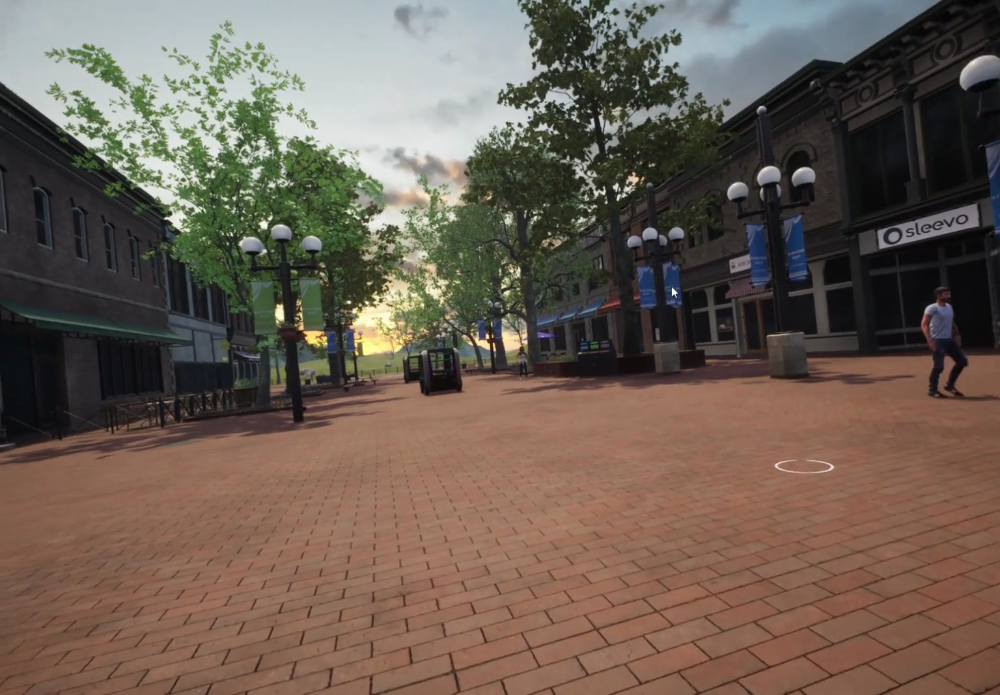
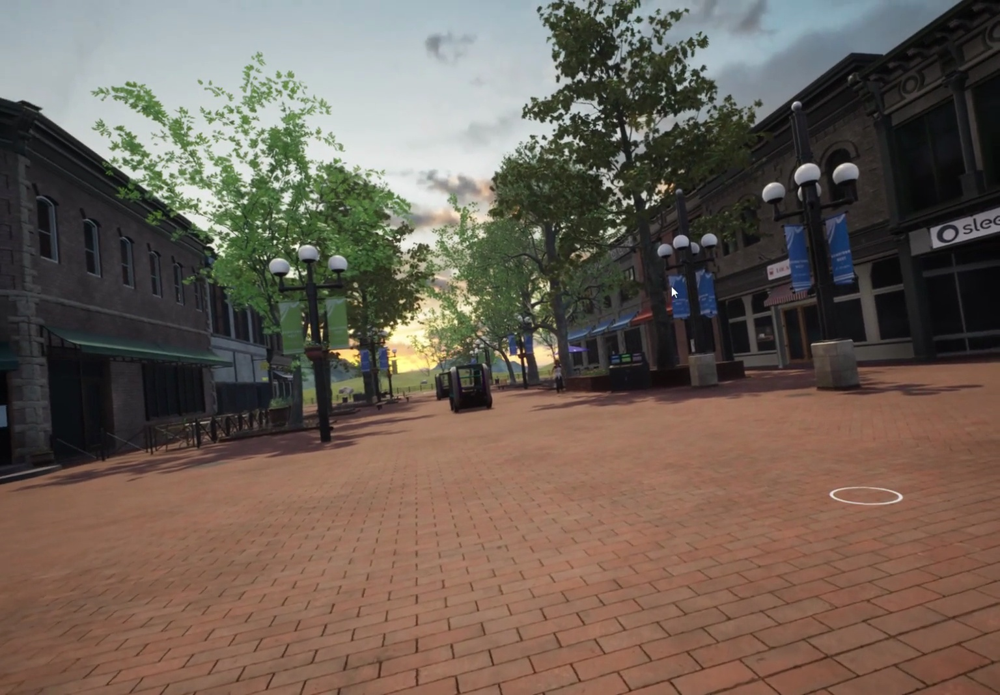
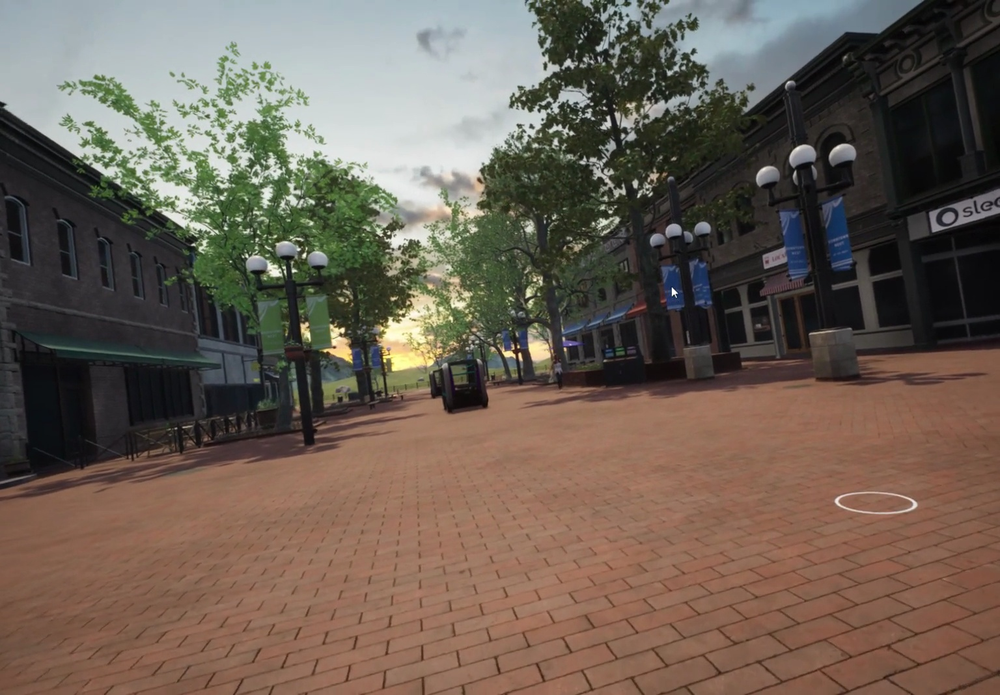
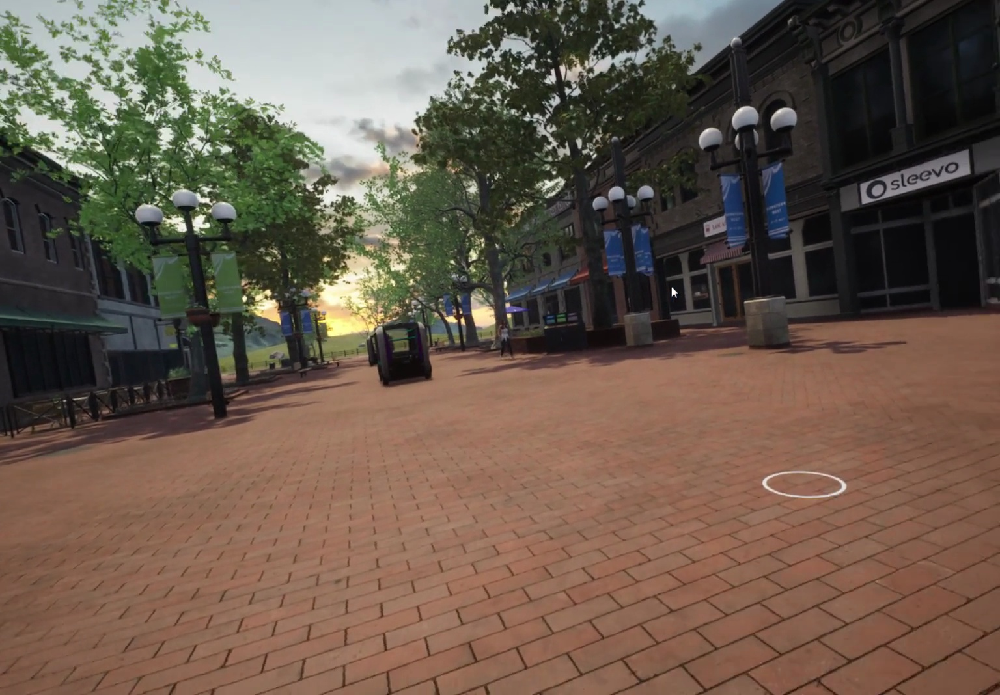
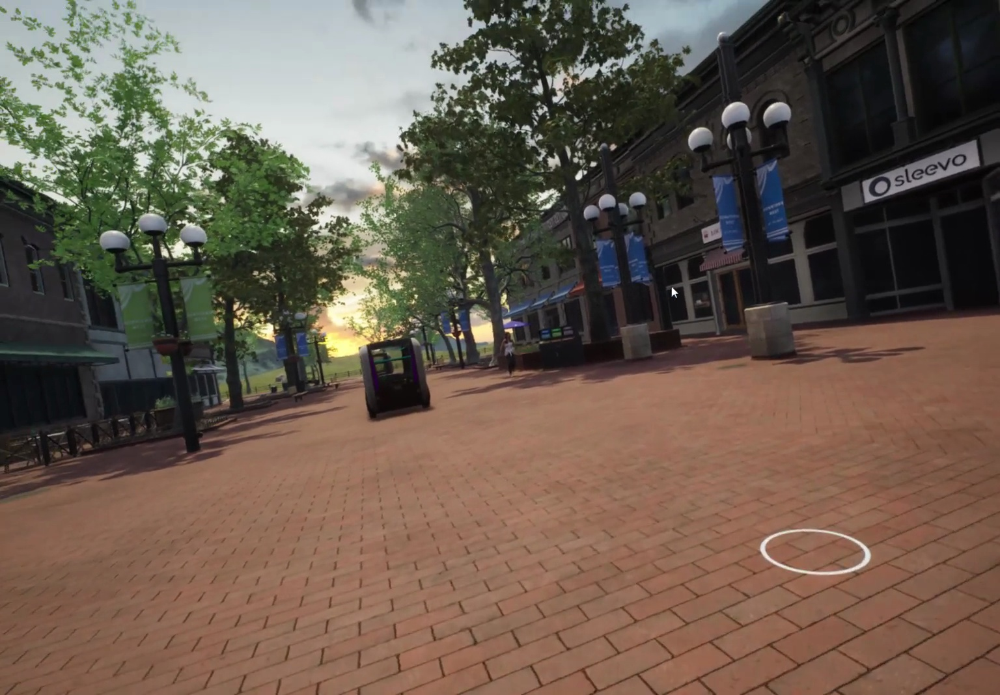

In [67]:
image_messages

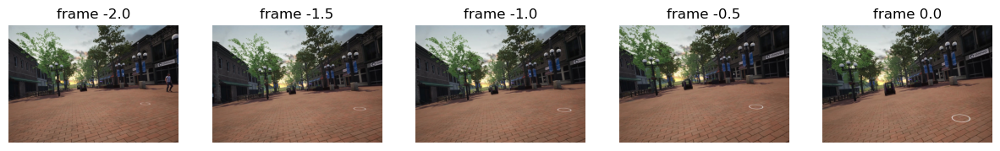

In [68]:
fig, axs = plt.subplots(1, len(images), figsize=(15, 5))
for ax, imgfile in zip(axs, images):
    # read image
    img_data = cv2.imread(imgfile['path'])
    img_data = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)
    ax.imshow(img_data)
    ax.set_title(f'frame {imgfile["time elapsed"]}')
    ax.axis('off')
plt.show()

[{'type': 'input_text',
  'text': "\nAnalyze the provided consecutive first-person video frames of a viewer interacting with automated pods in a shared space.\n\n0. Coordinate system\nThe reference system is defined relative to the automated pod's movement:\nX-Axis: Set along the pod's moving direction (moving forward as the positive direction). Movement on this axis is referred to as horizontal movement.\nY-Axis: Set perpendicular to the pod's path (pointing from right to left in the image as positive direction). Movement on this axis is referred to as lateral movement.\n\n1. Context:\nGoal: The white circle on the ground indicates the viewer's target position, which is on the other side of the pod. \nViewer Body Orientation: generally oriented toward the goal position.\nImages: The frames represent the current head/eye-level view based on the viewer's head direction.\n\n2. Dynamic and Spatial Inference\nBased on visual evidence (changes in perspective, size, and relative positions) a
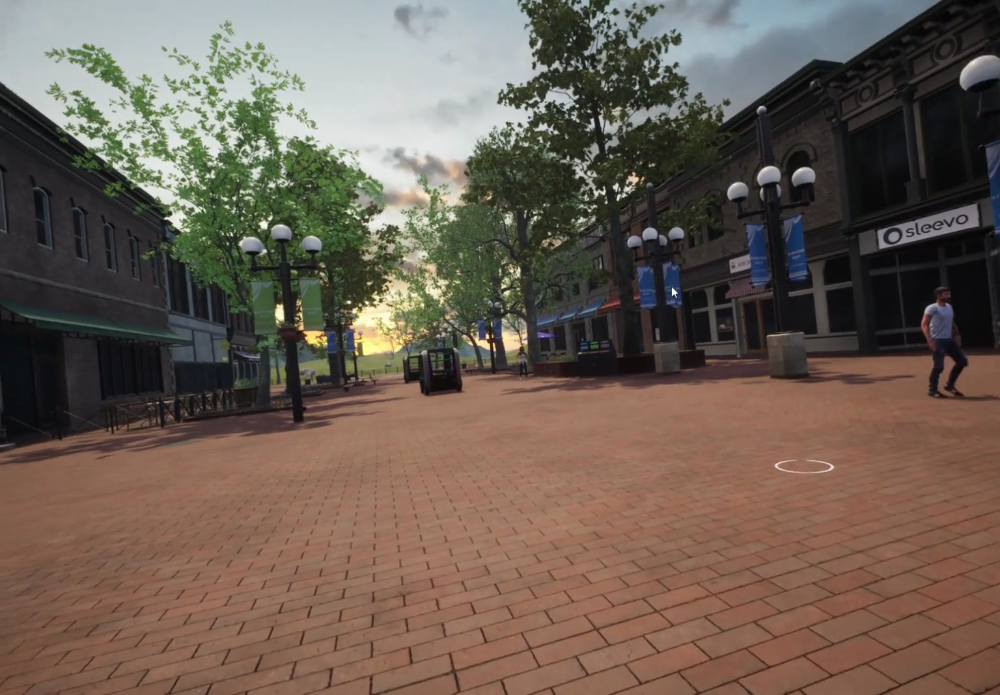
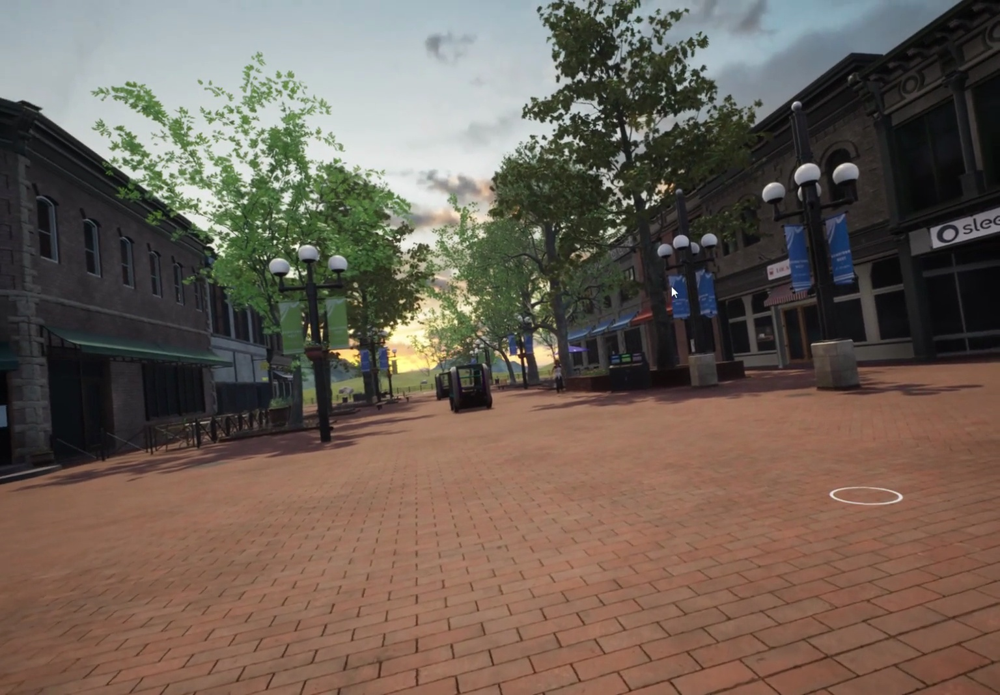
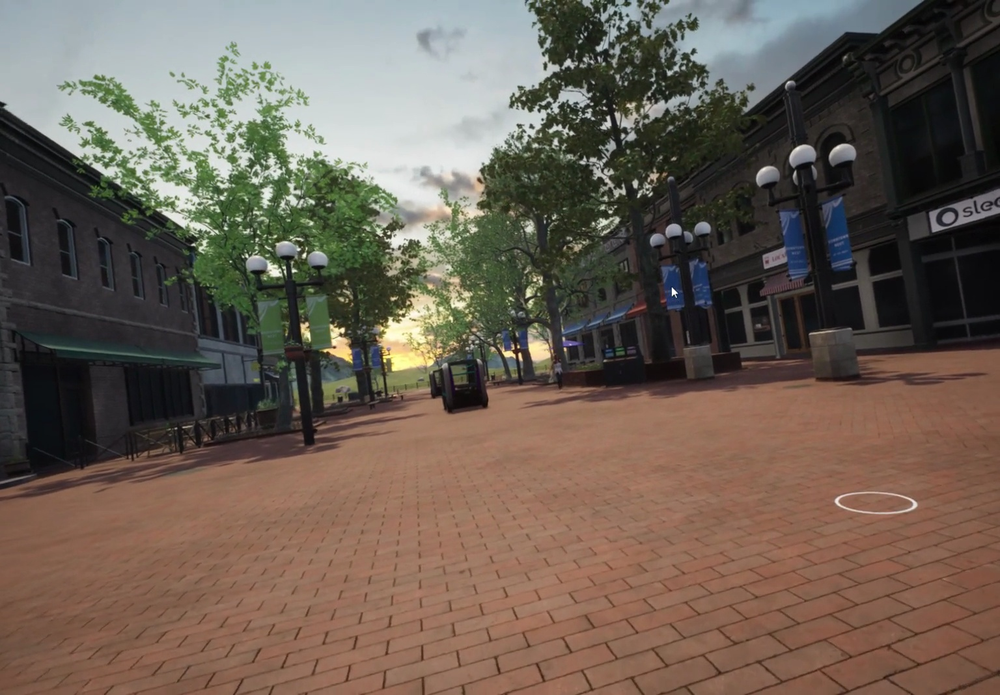
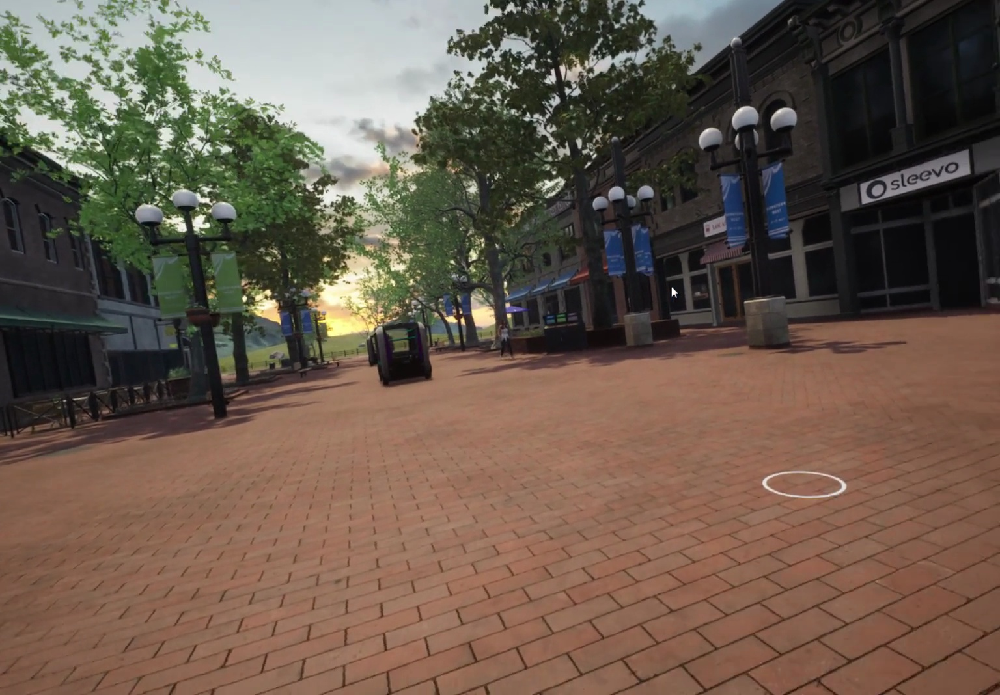
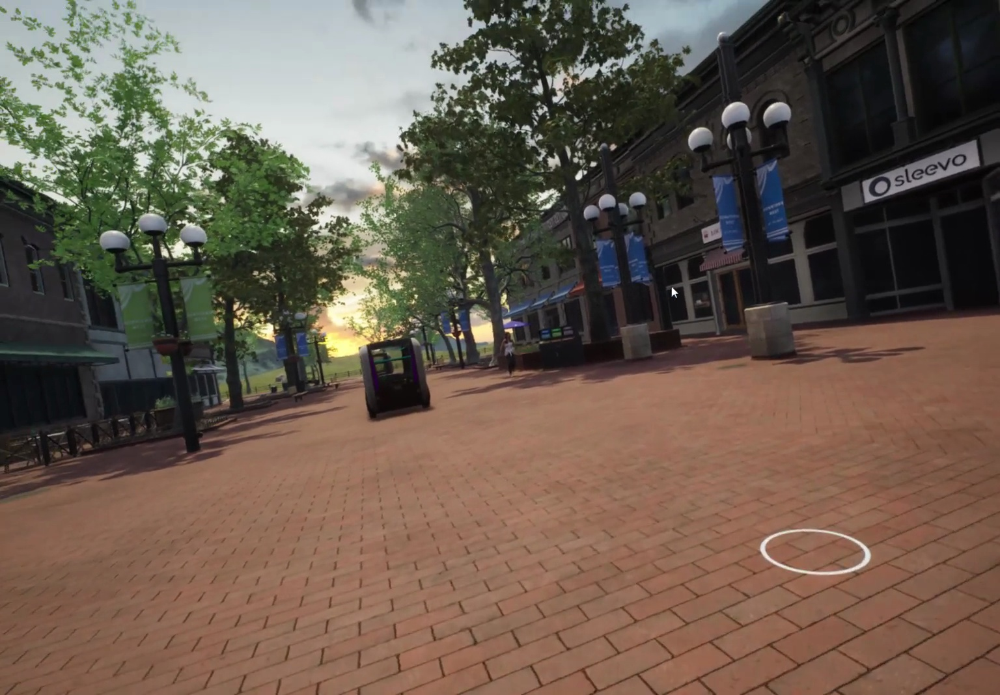

In [80]:
content = [
    {
        "type": "input_text",
        "text": '''
Analyze the provided consecutive first-person video frames of a viewer interacting with automated pods in a shared space.

0. Coordinate system
The reference system is defined relative to the automated pod's movement:
X-Axis: Set along the pod's moving direction (moving forward as the positive direction). Movement on this axis is referred to as horizontal movement.
Y-Axis: Set perpendicular to the pod's path (pointing from right to left in the image as positive direction). Movement on this axis is referred to as lateral movement.

1. Context:
Goal: The white circle on the ground indicates the viewer's target position, which is on the other side of the pod. 
Viewer Body Orientation: generally oriented toward the goal position.
Images: The frames represent the current head/eye-level view based on the viewer's head direction.

2. Dynamic and Spatial Inference
Based on visual evidence (changes in perspective, size, and relative positions) across consecutive frames, infer the following kinematic and spatial data:
Viewer Position: Infer the viewer's current position relative to the pods and the goal (e.g., nearing an intersection, adjacent to a pod, mid-path).
Viewer Movement Type: Is the viewer moving significantly along the X-axis (horizontal movement, positive or negative direction)? Is the viewer moving significantly along the Y-axis (lateral movement, positive or negative direction)?
Viewer Status: Is the viewer speeding up, maintaining speed, or decelerating (change in X and Y velocity)?
Pod Status: Is the automated pod accelerating, maintaining speed, or decelerating?
Estimate the distance between the viewer and pods, both lateral and horizontal. 

3. Interaction, Safety, and Intent Analysis
Gaze and Attention: What specific objects or areas (pods, ground, goal, periphery) could the viewer pay attention to?
Safety & Communication: Provide insights into potential safety concerns (e.g., proximity, sight lines, potential collision points) or observable communication signals (e.g., a deliberate head turn, a pod's change in speed/direction, or light signals).
Crossing Intent: Based on all the analyses, does the viewer intend to move to the other side of the road within the next 1.5 seconds? Provide a clear answer with supporting rationales and a confidence score. 
''',}
]
content.extend(image_messages)

content

In [81]:
%%time
response = client.responses.create(
    model="gpt-5",
    input=[
        {
            "role": "user",
            "content": content,
        }
    ]
)

CPU times: user 25.9 ms, sys: 26.7 ms, total: 52.6 ms
Wall time: 1min 22s


In [83]:
112/36

3.111111111111111

In [82]:
print(response.output_text)

2. Dynamic and spatial inference

Viewer position
- Near side of the pod’s path on the right side of the walkway, approaching the intended crossing point (white circle). The closer pod is between the viewer and the goal.

Viewer movement
- X-axis (along pod travel): little to no net movement; the global scene depth does not change much around the viewer.
- Y-axis (lateral): clear movement toward the right side of the image → negative Y direction. The pod shifts left in the frame while the white circle grows and moves closer, consistent with the viewer stepping rightward toward the goal.
- Speed trend: lateral speed roughly steady, possibly a slight increase from -1.5 s to -0.5 s and then stabilizing by 0.0 s.

Pod status
- The nearer pod is moving toward the viewer along +X (it grows steadily in size). Apparent speed looks roughly constant; no strong visual cue of braking or acceleration.
- A second pod is farther back in the same lane, also moving toward the viewer at similar pace.

D

In [ ]:
# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

file = 'P1S3'
frame_number = 105
images = [
    {"path": f"../data/videoframes/{file}/frame_000{frame_number:03d}.jpg", "time elapsed": "-2.0"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 9:03d}.jpg", "time elapsed": "-1.75"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 18:03d}.jpg", "time elapsed": "-1.5"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 27:03d}.jpg", "time elapsed": "-1.25"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 36:03d}.jpg", "time elapsed": "-1.0"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 45:03d}.jpg", "time elapsed": "-0.75"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 54:03d}.jpg", "time elapsed": "-0.5"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 63:03d}.jpg", "time elapsed": "-0.25"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 72:03d}.jpg", "time elapsed": "0.0"},
]

image_messages = []
for img in images:
    image_messages.append({"type": "input_text", "text": f"Image at {img['time elapsed']} seconds."})
    image_messages.append({"type": "input_image", "image_url": f"data:image/jpeg;base64,{encode_image(img['path'])}", "detail": "low"})

In [127]:
105/36, (105+72)/36

(2.9166666666666665, 4.916666666666667)

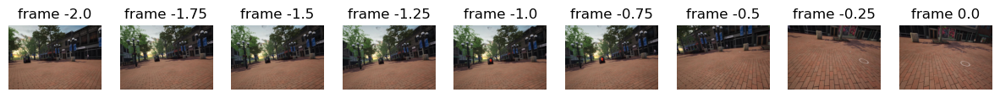

In [121]:
fig, axs = plt.subplots(1, len(images), figsize=(15, 5))
for ax, imgfile in zip(axs, images):
    # read image
    img_data = cv2.imread(imgfile['path'])
    img_data = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)
    ax.imshow(img_data)
    ax.set_title(f'frame {imgfile["time elapsed"]}')
    ax.axis('off')
plt.show()

[{'type': 'input_text', 'text': 'Image at -2.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.75 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.25 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.75 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.25 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'i
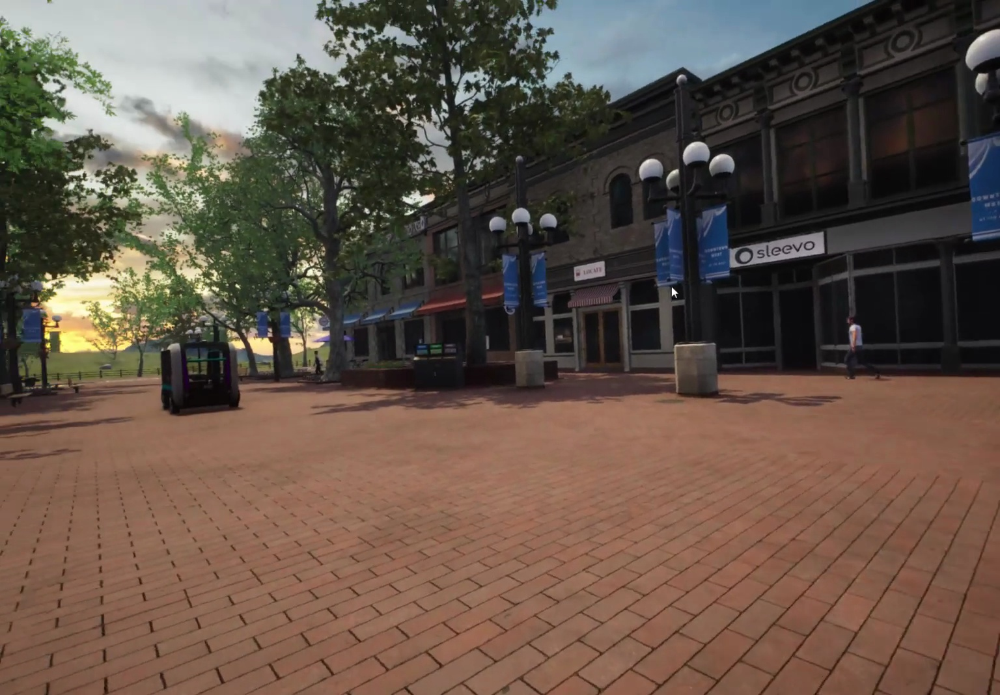
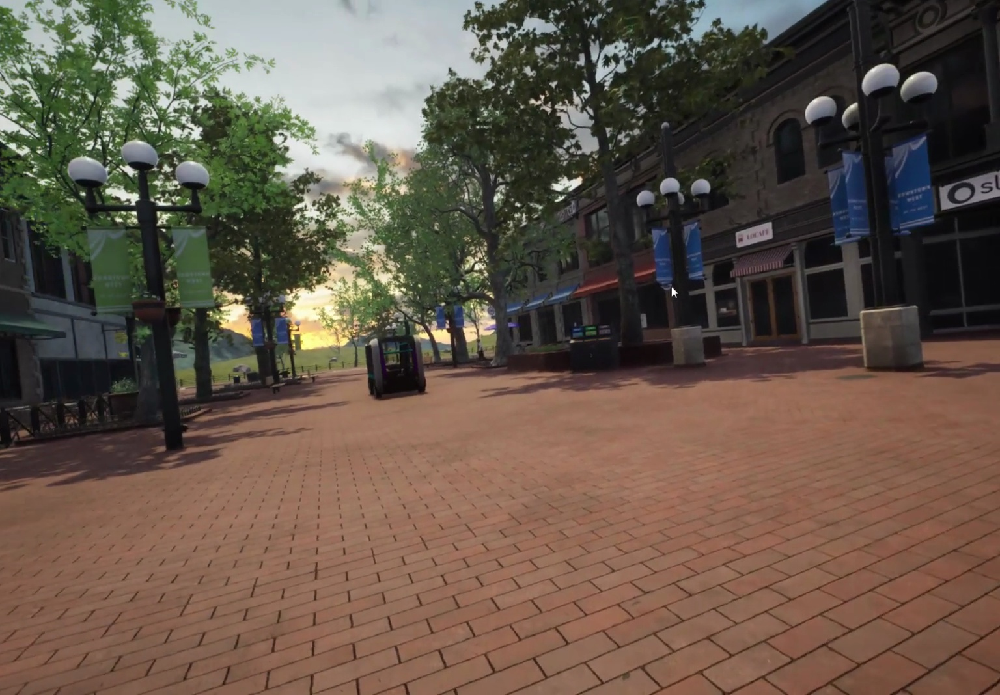
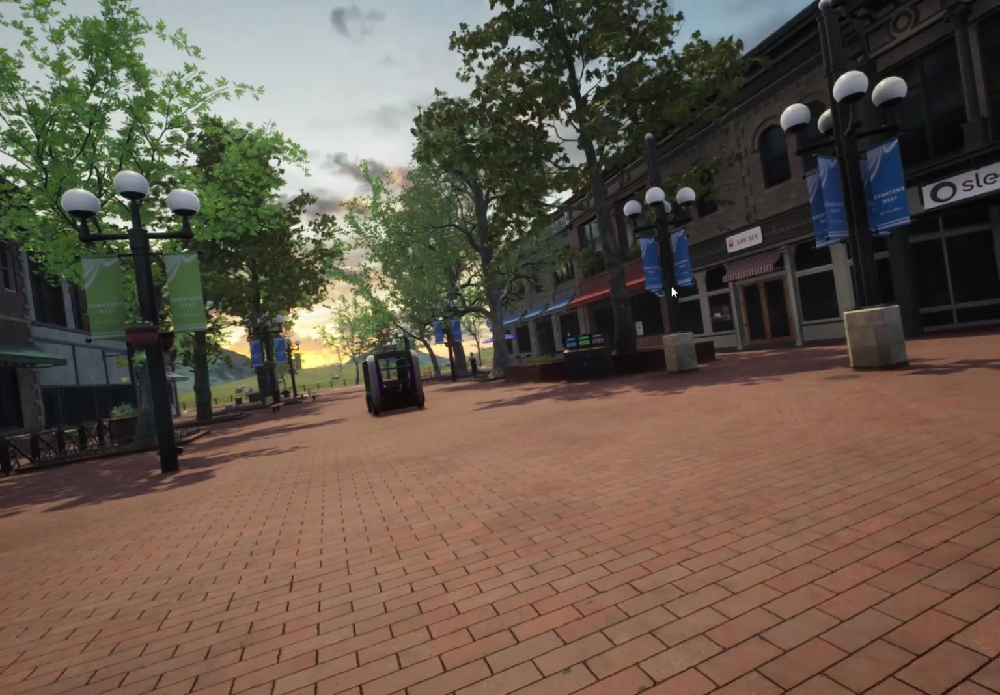
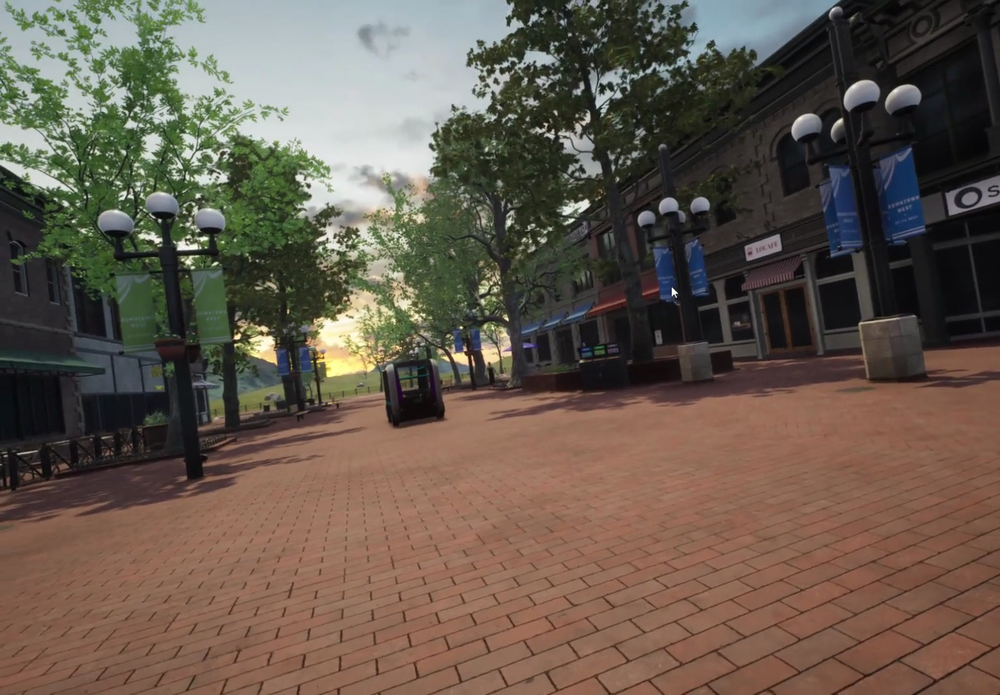
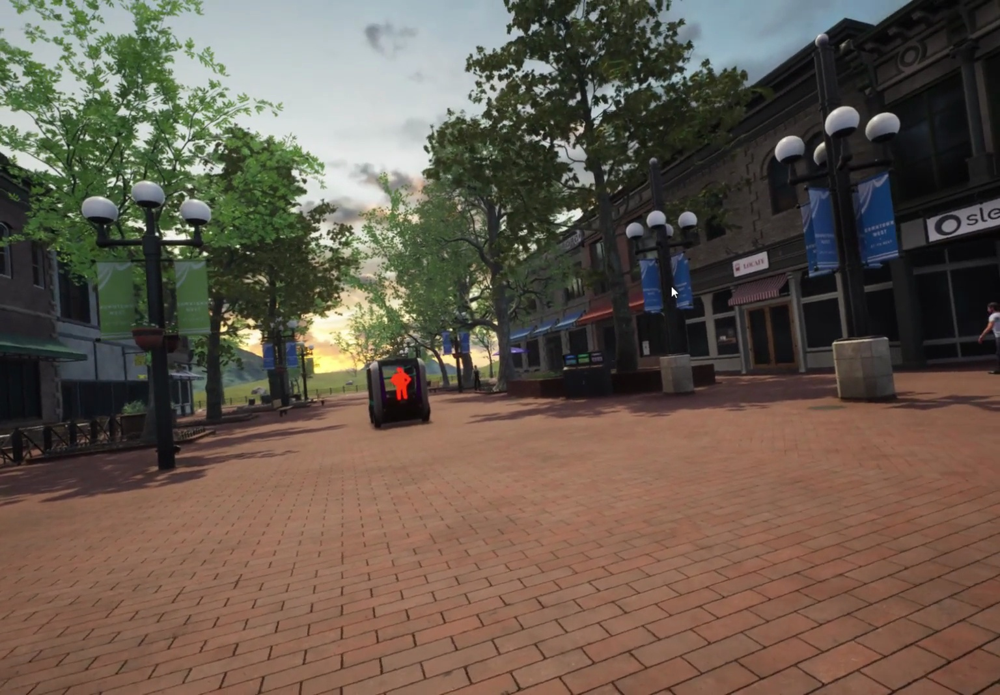
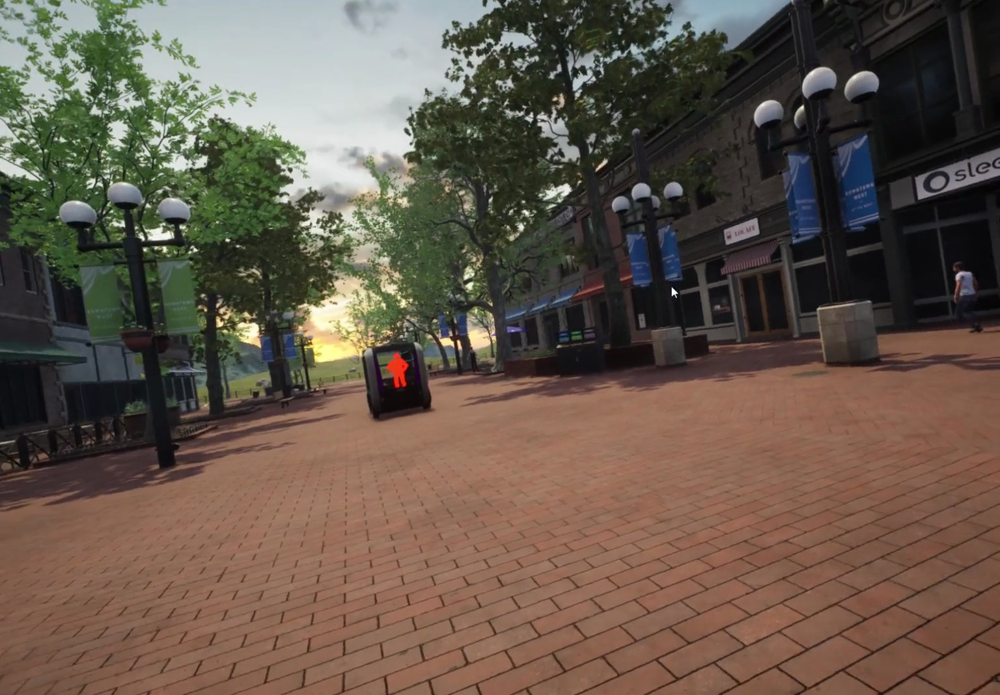
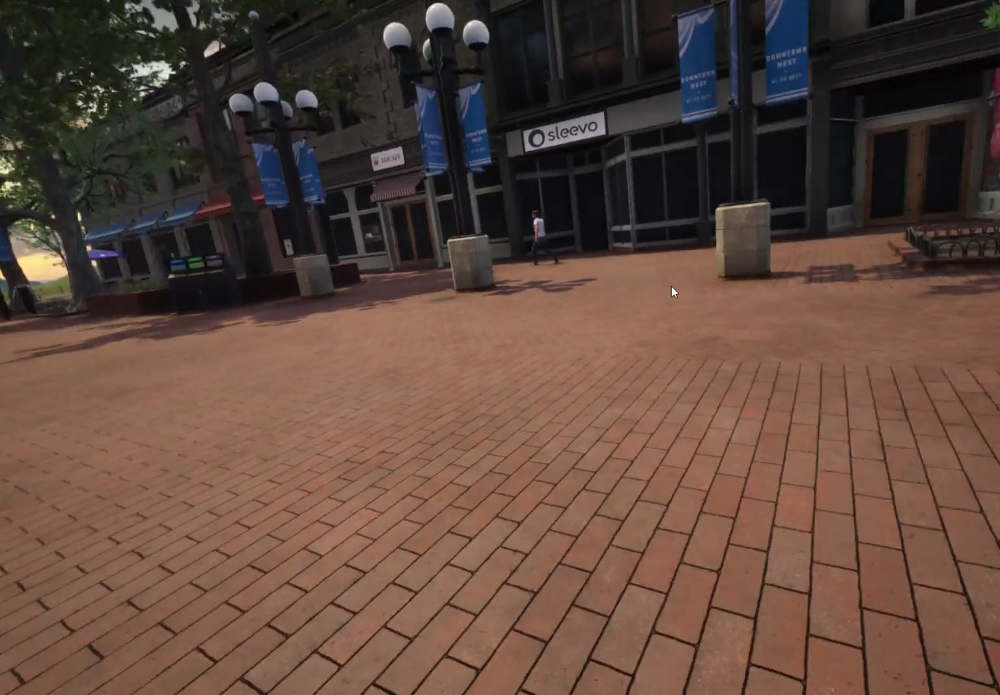
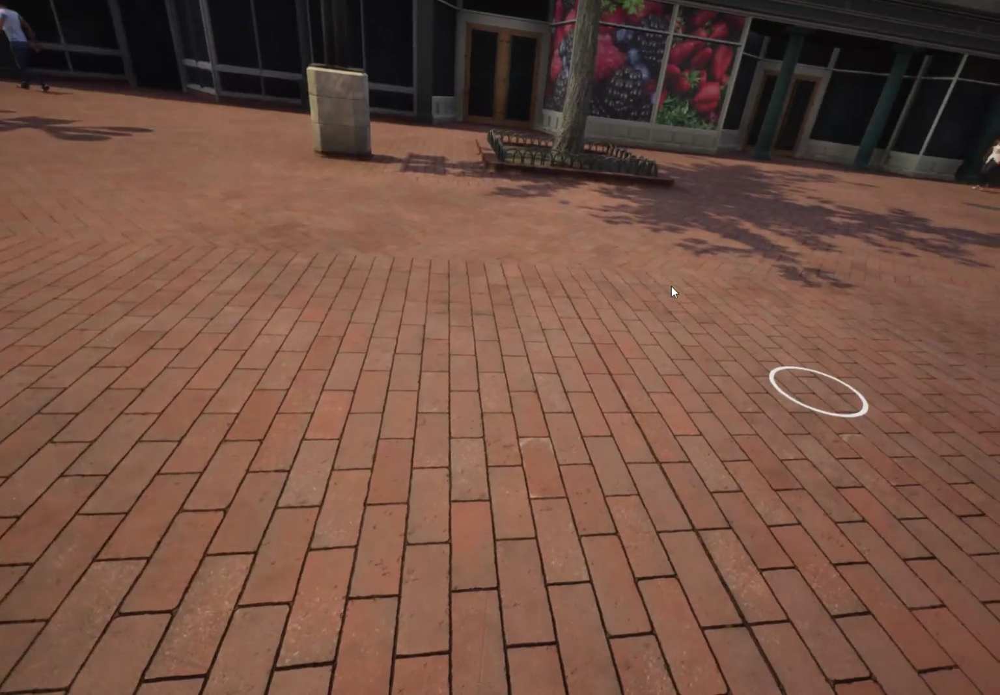
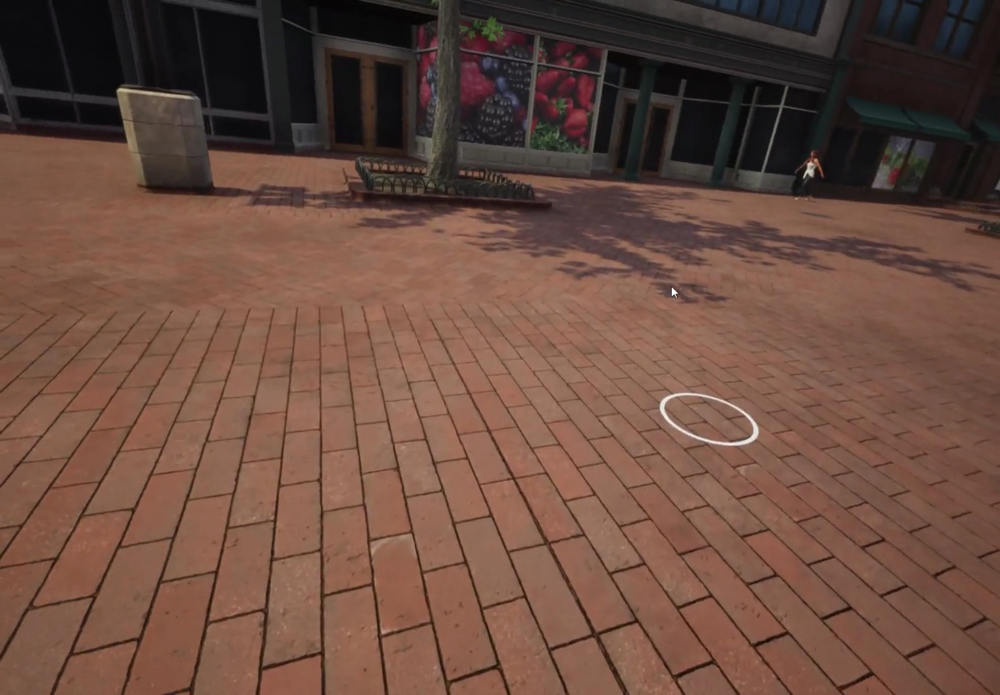

In [122]:
image_messages

[{'type': 'input_text',
  'text': "\nAnalyze the provided consecutive first-person video frames of a viewer interacting with automated pods in a shared space.\n\n0. Coordinate system\nThe reference system is defined relative to the automated pod's movement:\nX-Axis: Set along the pod's moving direction (horizontal movement). Positive X: same as the pod's travel direction (toward the viewer in these frames).\nY-Axis: Set perpendicular to the pod's path (lateral movement). Positive Y: leftward in the image; rightward motion is negative Y. \n\n1. Context:\nGoal: The white circle on the ground indicates the viewer's target position, which is on the other side of the pod. \nImages: The frames represent the current head/eye-level view based on the viewer's head direction.\nRed pedestrian signal on the pod: indicates that the pod will not yield to the pedestrian.\nGreen pedestrian signal on the pod: indicates that the pod will yield to the pedestrian.\nBoth signals are suggestive of the pod's
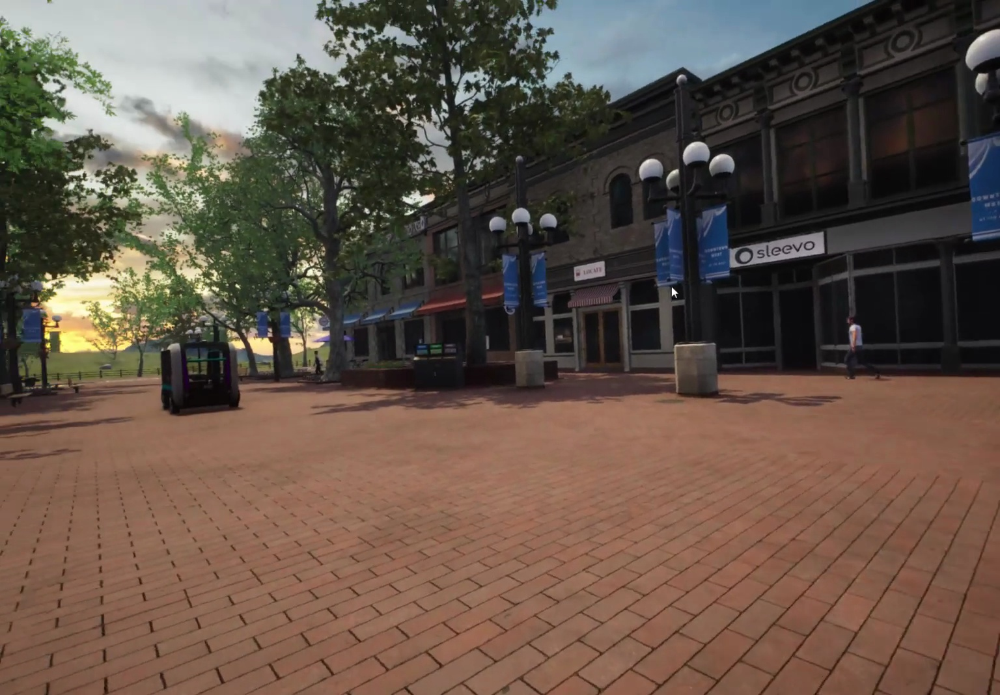
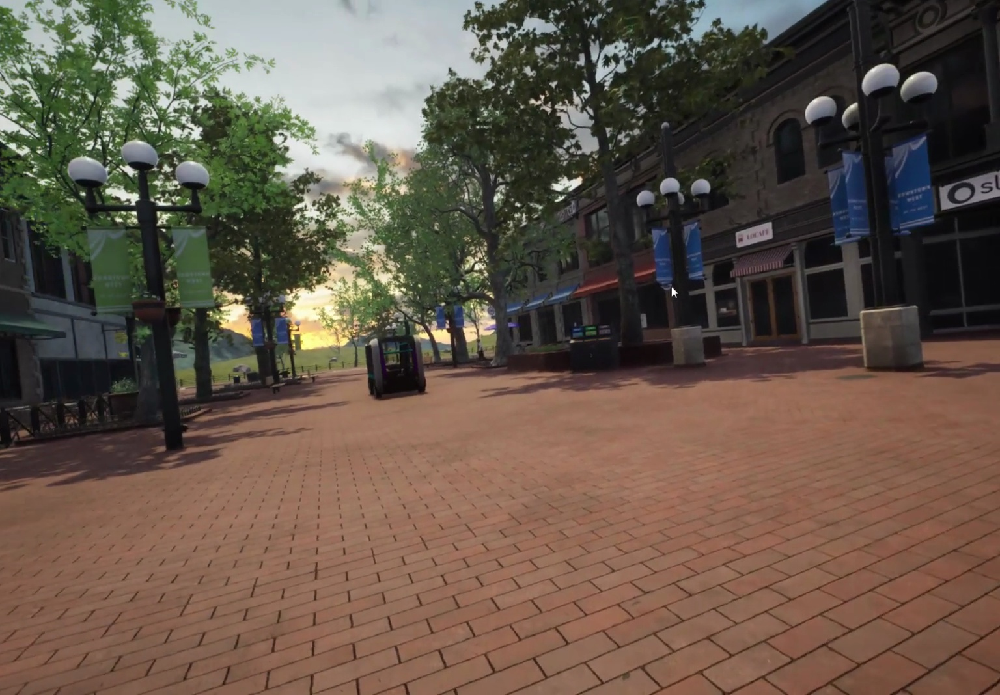
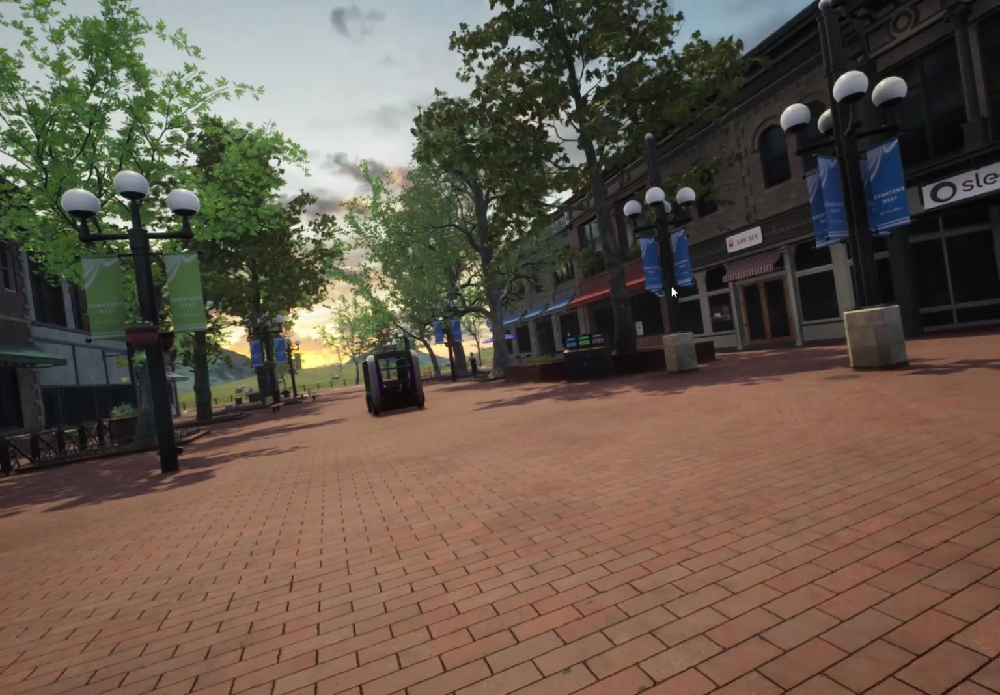
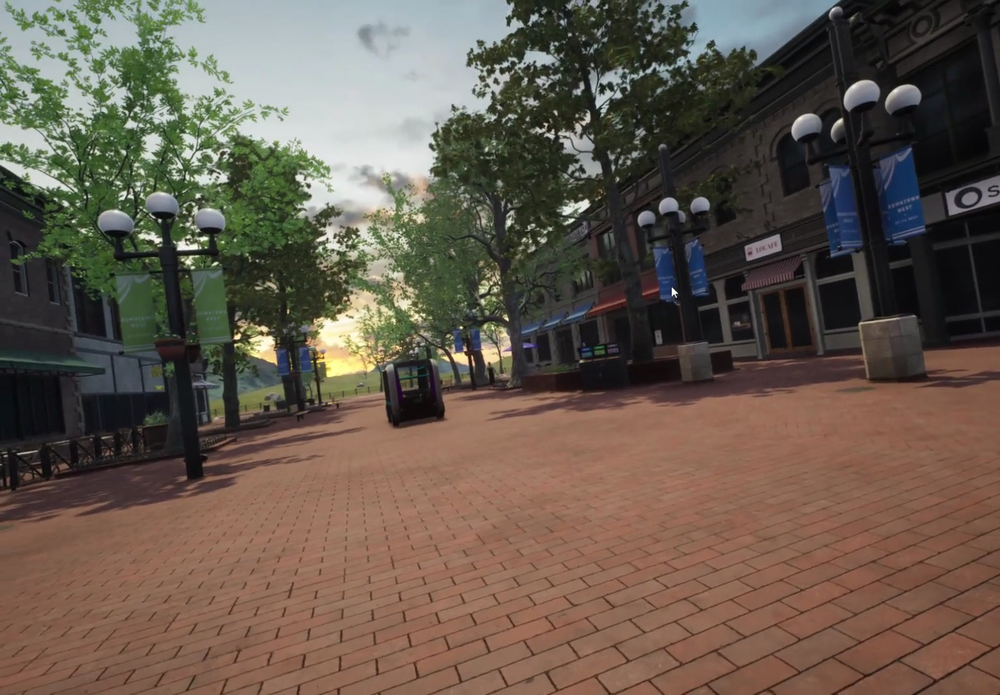
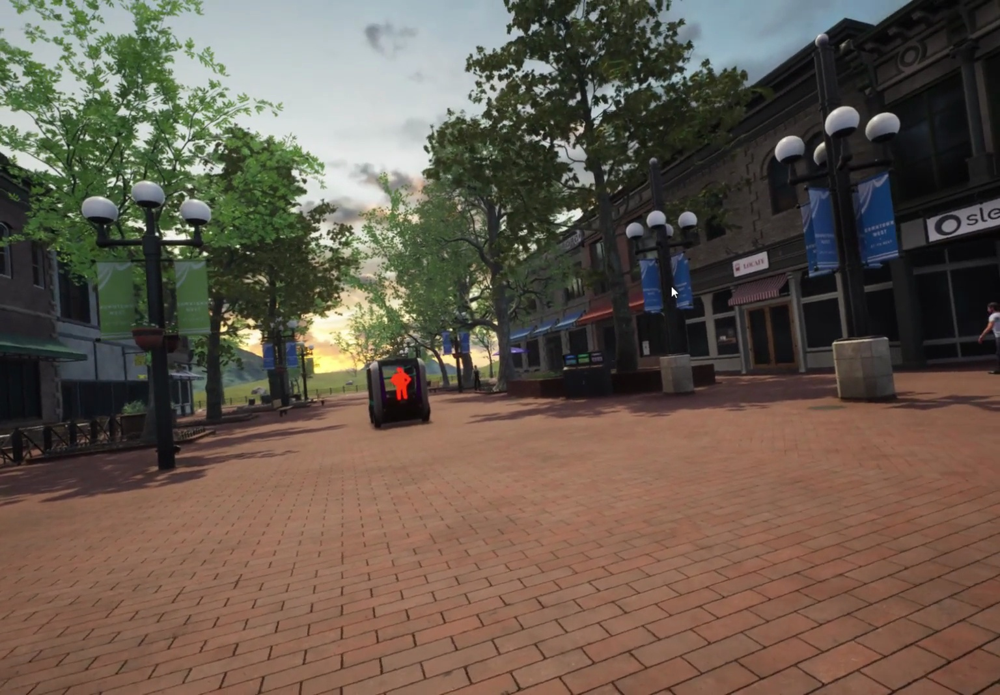
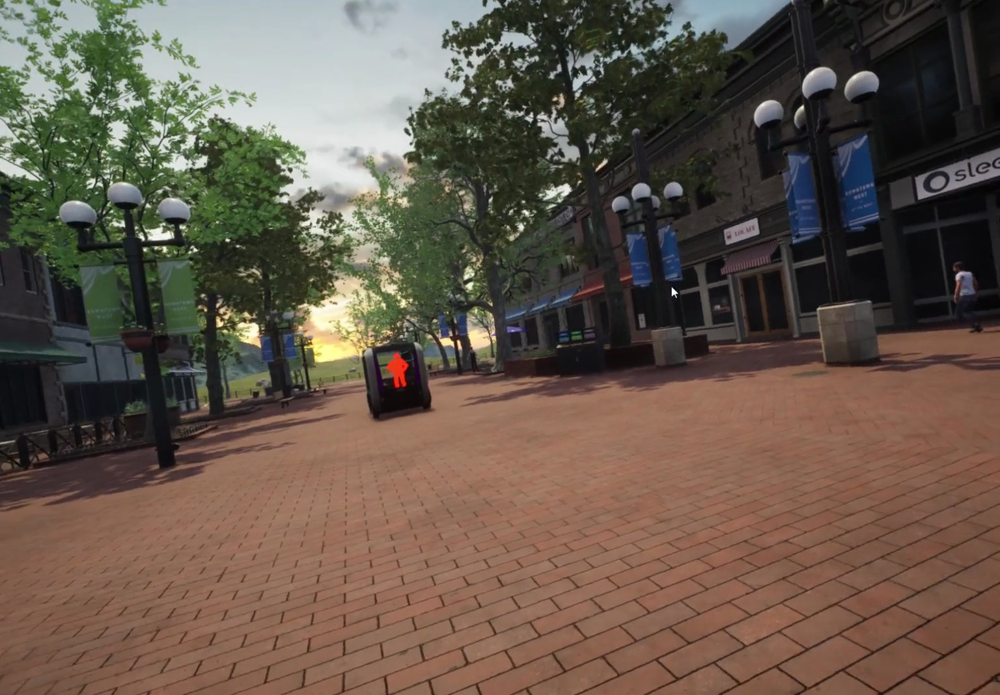
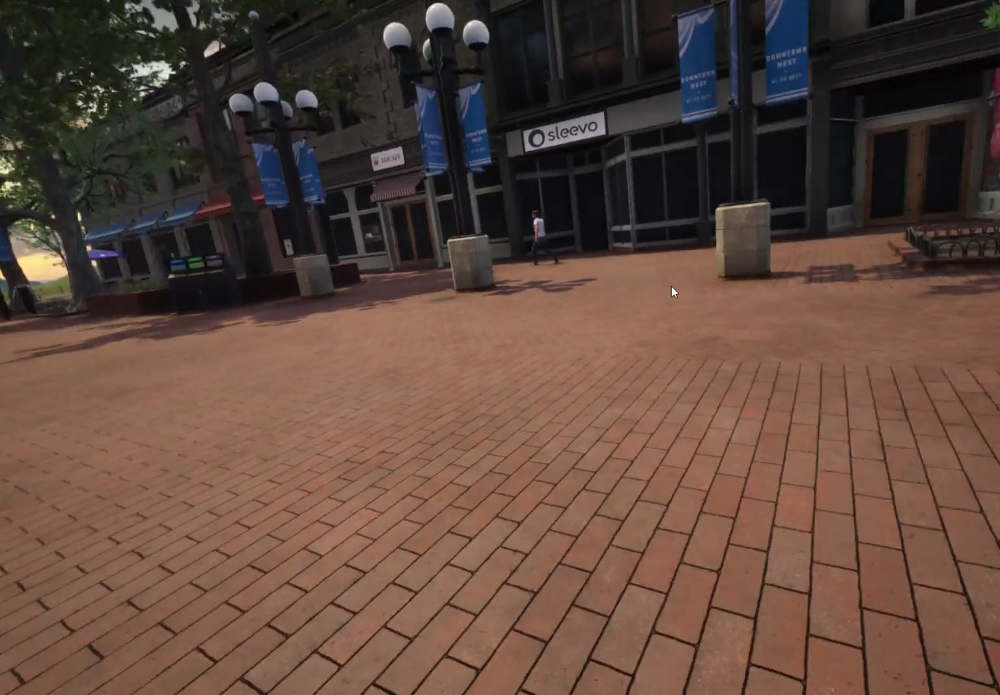
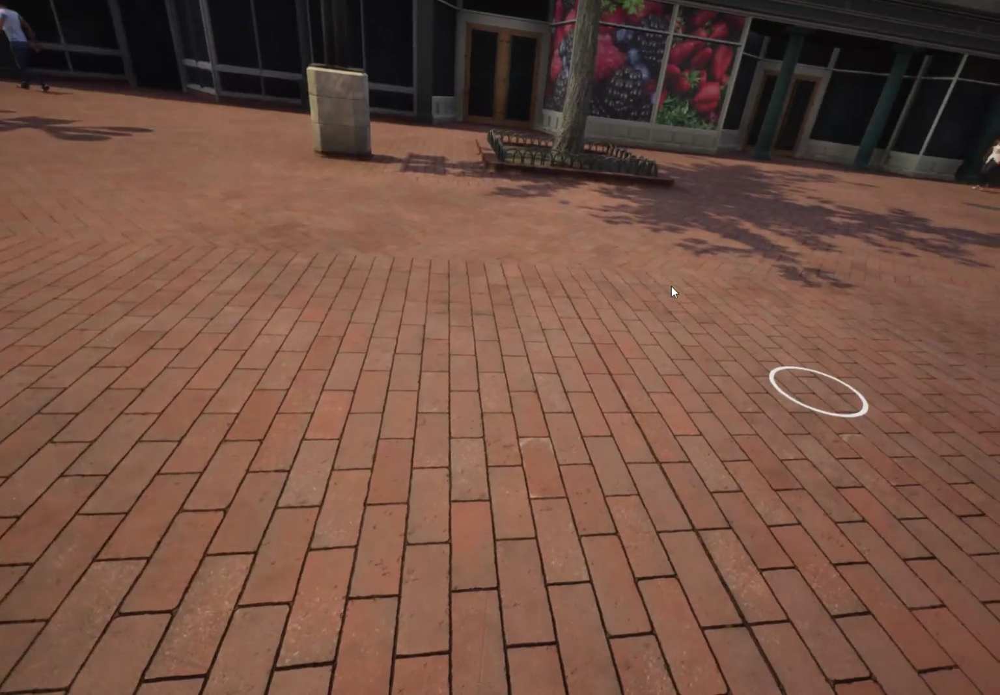
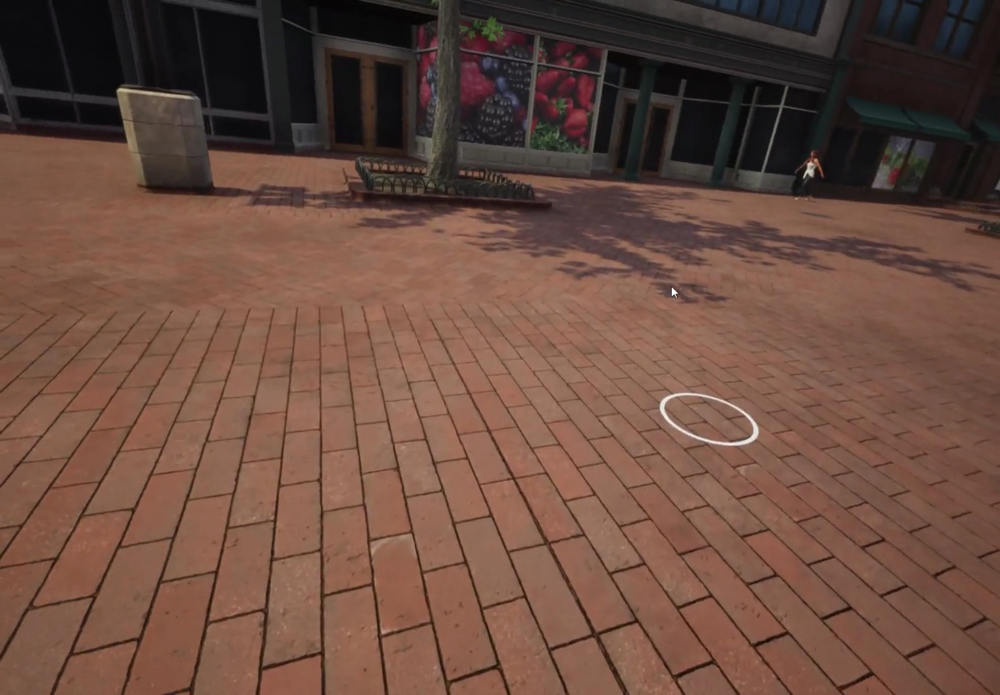

In [123]:
content = [
    {
        "type": "input_text",
        "text": '''
Analyze the provided consecutive first-person video frames of a viewer interacting with automated pods in a shared space.

0. Coordinate system
The reference system is defined relative to the automated pod's movement:
X-Axis: Set along the pod's moving direction (horizontal movement). Positive X: same as the pod's travel direction (toward the viewer in these frames).
Y-Axis: Set perpendicular to the pod's path (lateral movement). Positive Y: leftward in the image; rightward motion is negative Y. 

1. Context:
Goal: The white circle on the ground indicates the viewer's target position, which is on the other side of the pod. 
Images: The frames represent the current head/eye-level view based on the viewer's head direction.
Red pedestrian signal on the pod: indicates that the pod will not yield to the pedestrian.
Green pedestrian signal on the pod: indicates that the pod will yield to the pedestrian.
Both signals are suggestive of the pod's intent, and the viewer doesn't need to follow it.

2. Dynamic and Spatial Inference
Based on visual evidence (changes in perspective, size, and relative positions) across consecutive frames, infer the following kinematic and spatial data:
Viewer Position: Infer the viewer's current position relative to the pods and the goal (e.g., nearing an intersection, adjacent to a pod, mid-path).
Viewer Movement Type: Is the viewer moving significantly along the X-axis (horizontal movement, positive or negative direction)? Is the viewer moving significantly along the Y-axis (lateral movement, positive or negative direction)?
Viewer Status: Is the viewer speeding up, maintaining speed, or decelerating (change in X and Y velocity)?
Pod Status: Is the automated pod accelerating, maintaining speed, or decelerating?
Estimate the distance between the viewer and pods, both lateral and horizontal. 

3. Interaction, Safety, and Intent Analysis
Gaze and Attention: What specific objects or areas (pods, ground, goal, periphery) could the viewer pay attention to?
Safety & Communication: Provide insights into potential safety concerns (e.g., proximity, sight lines, potential collision points) or observable communication signals (e.g., a deliberate head turn, a pod's change in speed/direction, or light signals).
Crossing Intent: Based on all the analyses, what could be the action of the next 1.5 seconds? Accelerate to the right, Maintain current speed, Decelerate to the right, Stop, Move backward. Provide a clear answer with supporting rationales and a confidence score.
''',}
]
content.extend(image_messages)

content

In [124]:
%%time
response = client.responses.create(
    model="gpt-5",
    input=[
        {
            "role": "user",
            "content": content,
        }
    ]
)

CPU times: user 51.5 ms, sys: 53.4 ms, total: 105 ms
Wall time: 1min 32s


In [125]:
print(response.output_text)

2. Dynamic and spatial inference

Viewer position
- -2.0 to -1.25 s: Viewer is in the open plaza, roughly centered, with one pod ahead slightly left of center. The goal (white circle) is on the far right side of the plaza (other side of the pod).
- -1.0 to -0.75 s: Viewer still mid‑plaza, pod approaching; pod shows a red pedestrian icon (will not yield).
- -0.5 to 0.0 s: Viewer moves to the right edge of the plaza toward the goal; by 0.0 s the circle is just in front-right and the pod is off to the left/out of frame.

Viewer movement type
- X (along pod travel): Small positive early (walking forward toward the pod), then reduced to near zero by -0.25 to 0.0 s.
- Y (lateral): Strong negative Y (to the right) from about -0.75 to -0.25 s as the viewer goes around the pod toward the goal; lateral motion decreases as the viewer reaches the circle.

Viewer status (speed trend)
- Accelerates laterally to the right between -0.75 and -0.5 s, then decelerates (both X and Y) while arriving at the

In [109]:
16888-18267

-1379

In [160]:
# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

file = 'P1S5'
frame_number = 40
images = [
    {"path": f"../data/videoframes/{file}/frame_000{frame_number:03d}.jpg", "time elapsed": "-2.0"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 9:03d}.jpg", "time elapsed": "-1.75"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 18:03d}.jpg", "time elapsed": "-1.5"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 27:03d}.jpg", "time elapsed": "-1.25"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 36:03d}.jpg", "time elapsed": "-1.0"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 45:03d}.jpg", "time elapsed": "-0.75"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 54:03d}.jpg", "time elapsed": "-0.5"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 63:03d}.jpg", "time elapsed": "-0.25"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 72:03d}.jpg", "time elapsed": "0.0"},
]

image_messages = []
for img in images:
    image_messages.append({"type": "input_text", "text": f"Image at {img['time elapsed']} seconds."})
    image_messages.append({"type": "input_image", "image_url": f"data:image/jpeg;base64,{encode_image(img['path'])}", "detail": "low"})

In [161]:
frame_number/36, (frame_number+72)/36

(1.1111111111111112, 3.111111111111111)

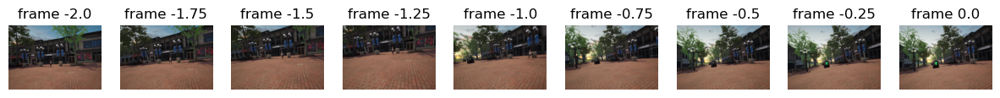

In [162]:
fig, axs = plt.subplots(1, len(images), figsize=(15, 5))
for ax, imgfile in zip(axs, images):
    # read image
    img_data = cv2.imread(imgfile['path'])
    img_data = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)
    ax.imshow(img_data)
    ax.set_title(f'frame {imgfile["time elapsed"]}')
    ax.axis('off')
plt.show()

[{'type': 'input_text', 'text': 'Image at -2.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.75 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.25 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.75 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.25 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'i
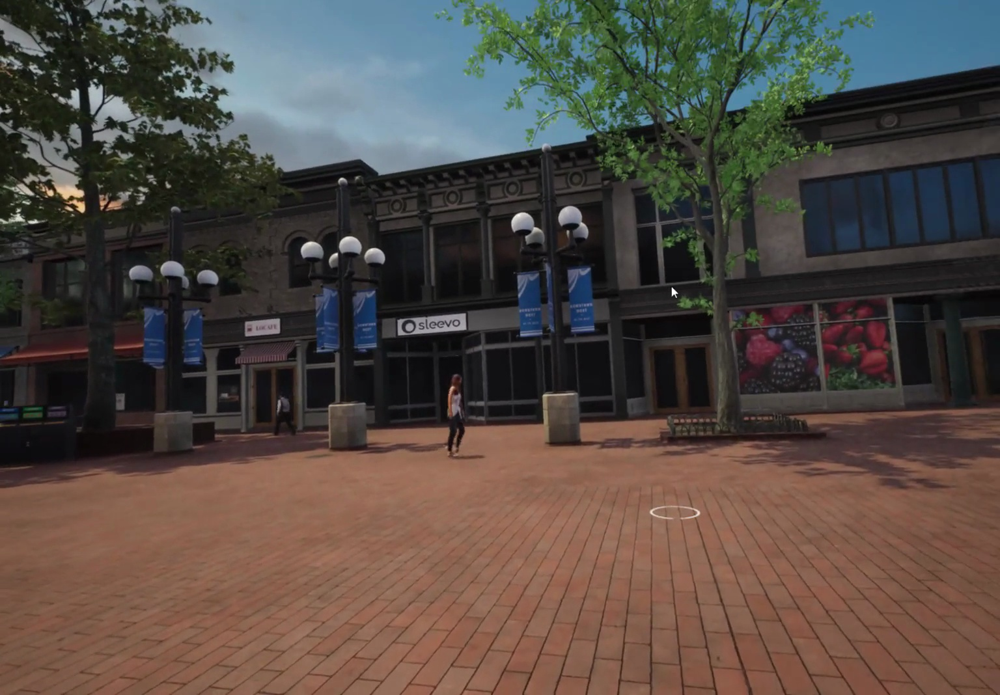
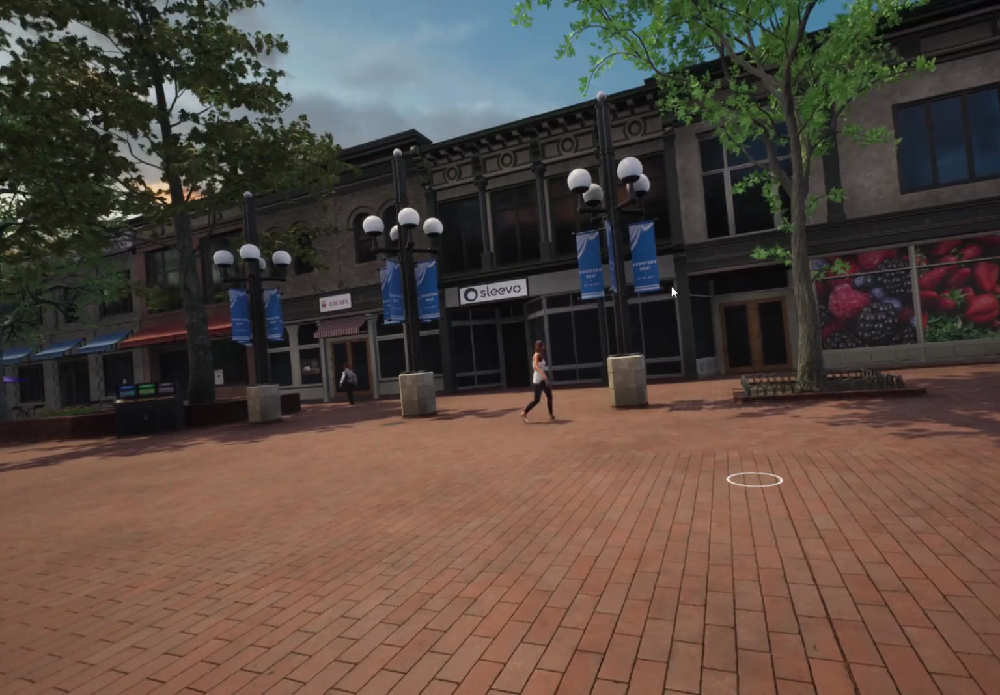
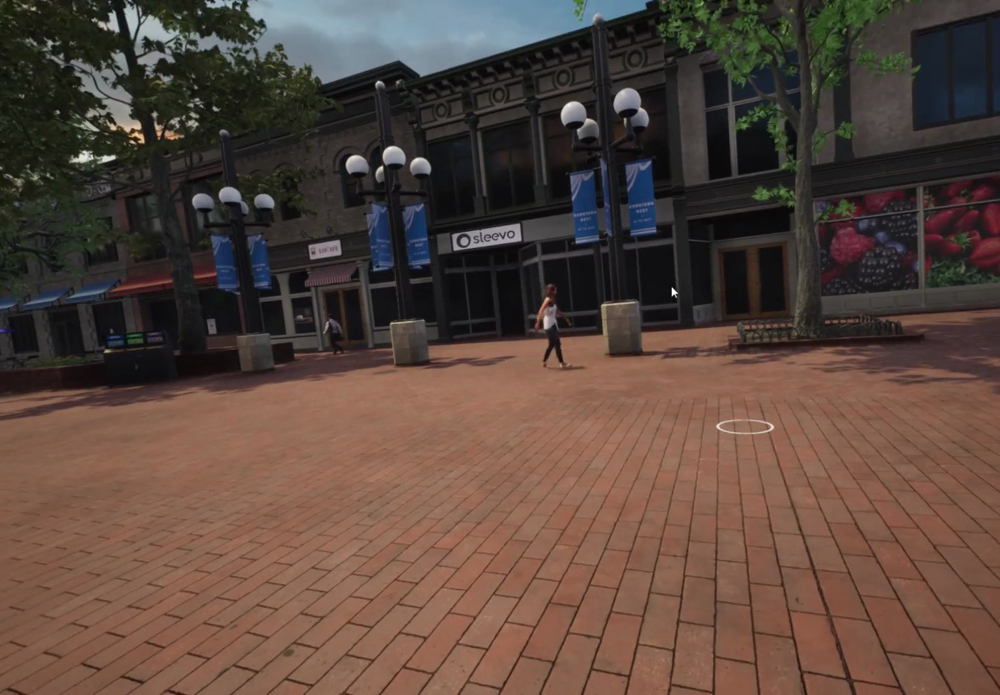
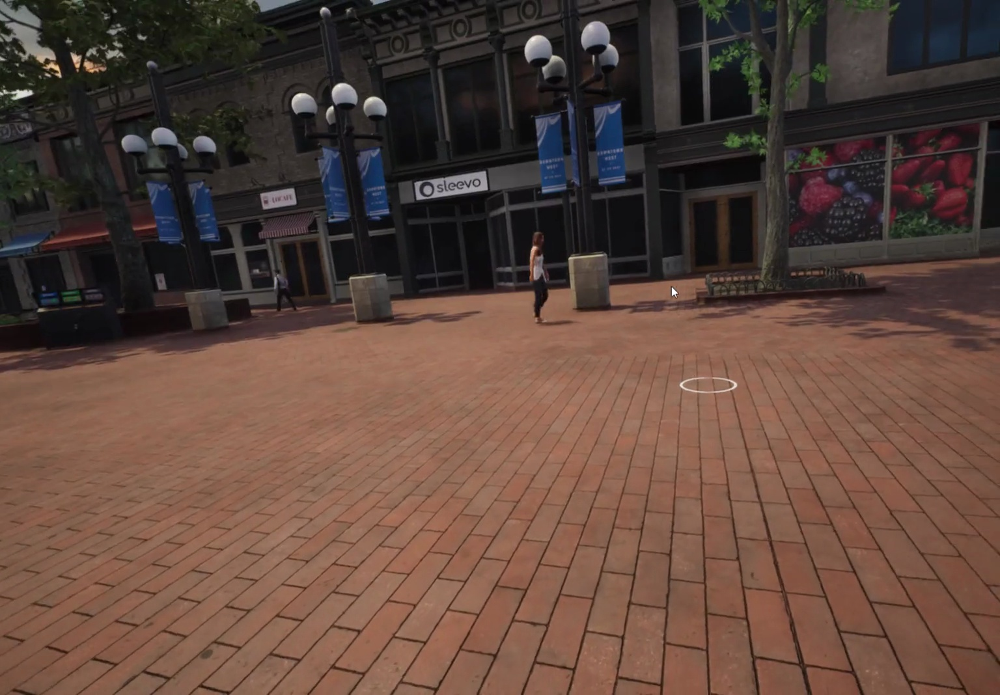
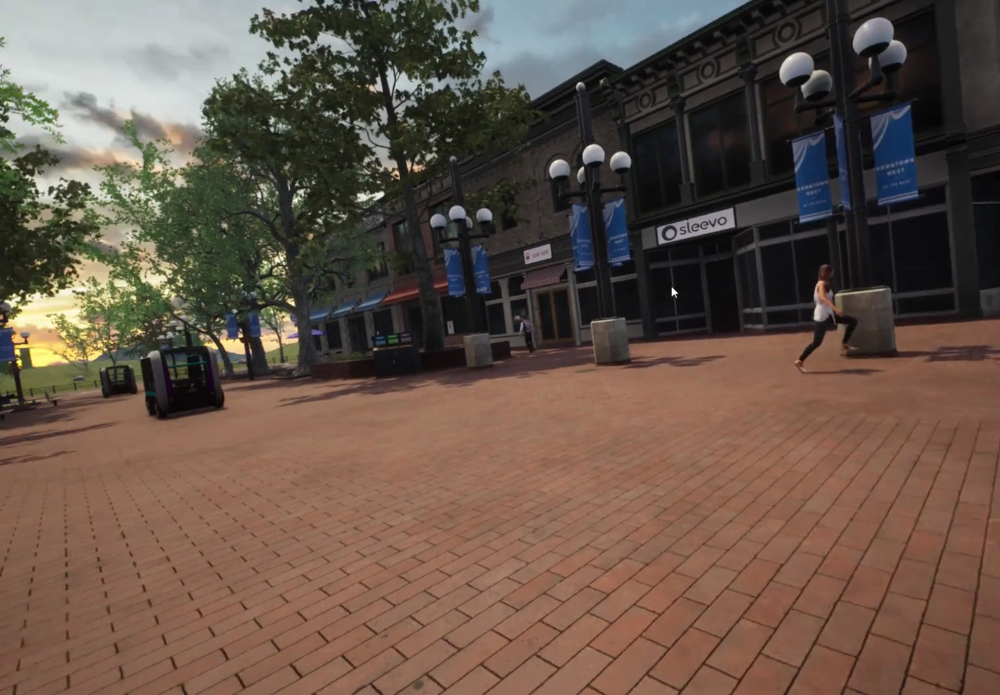
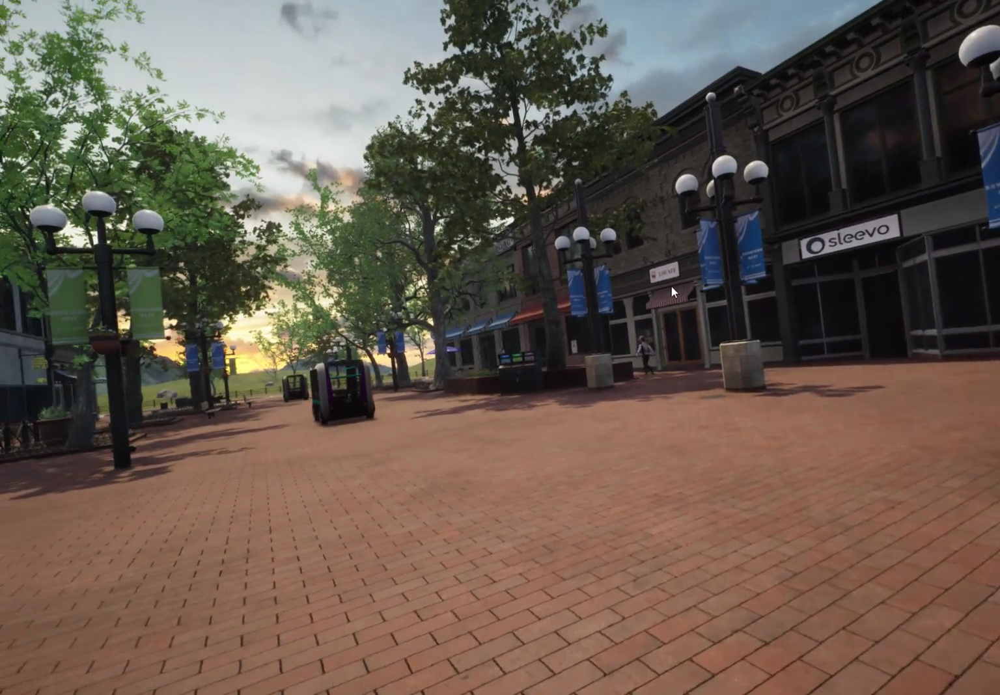
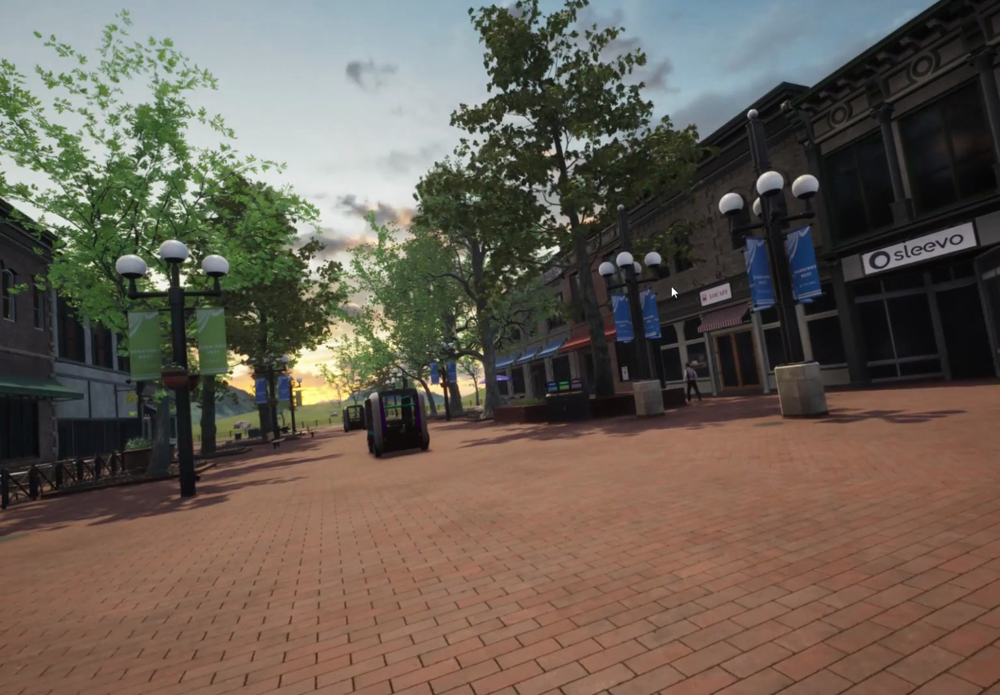
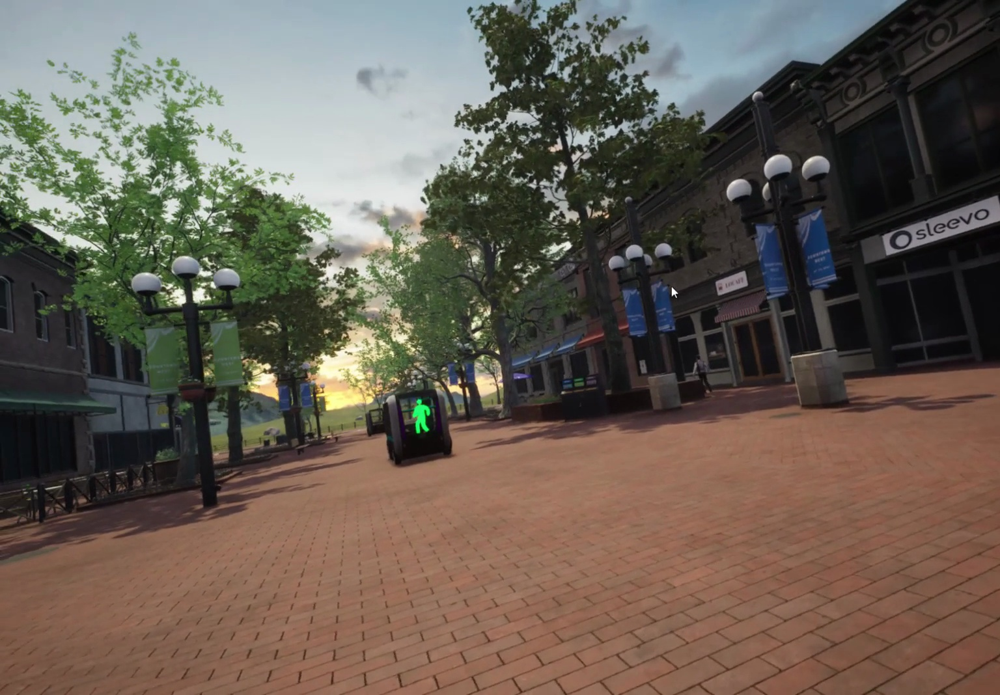
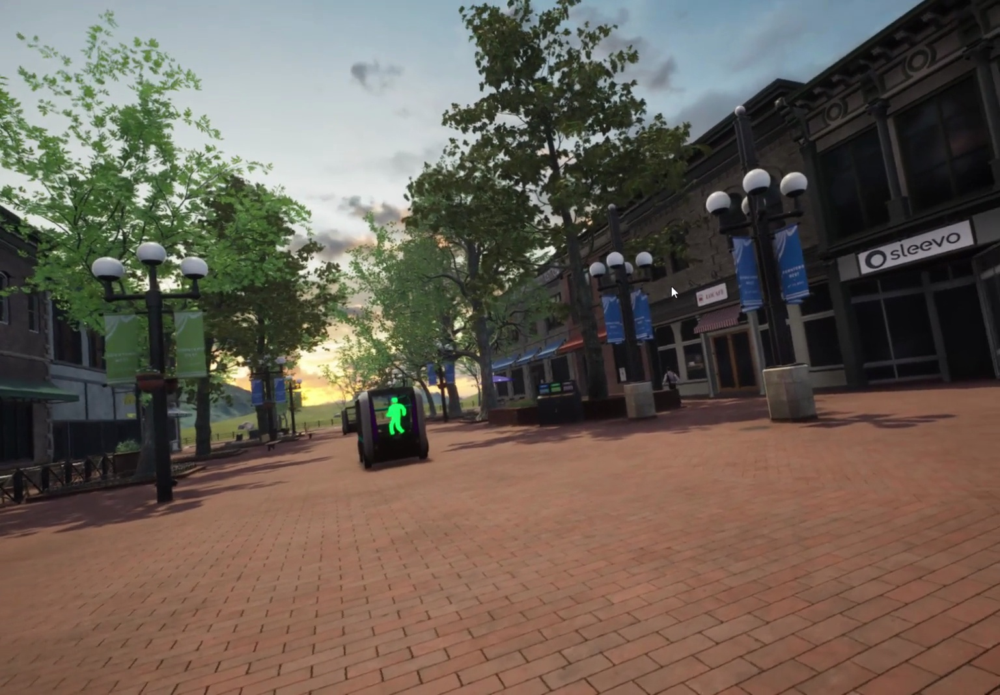

In [132]:
image_messages

[{'type': 'input_text',
  'text': "\nAnalyze the provided consecutive first-person video frames of a viewer interacting with automated pods in a shared space.\n\n0. Coordinate system\nThe reference system is defined relative to the automated pod's movement:\nX-Axis: Set along the pod's moving direction (horizontal movement). Positive X: same as the pod's travel direction (toward the viewer in these frames).\nY-Axis: Set perpendicular to the pod's path (lateral movement). Positive Y: leftward in the image; rightward motion is negative Y. \n\n1. Context:\nGoal: The white circle on the ground indicates the viewer's target position, which is on the other side of the pod. \nImages: The frames represent the current head/eye-level view based on the viewer's head direction.\nRed pedestrian signal on the pod: indicates that the pod will not yield to the pedestrian.\nGreen pedestrian signal on the pod: indicates that the pod will yield to the pedestrian.\nBoth signals are suggestive of the pod's
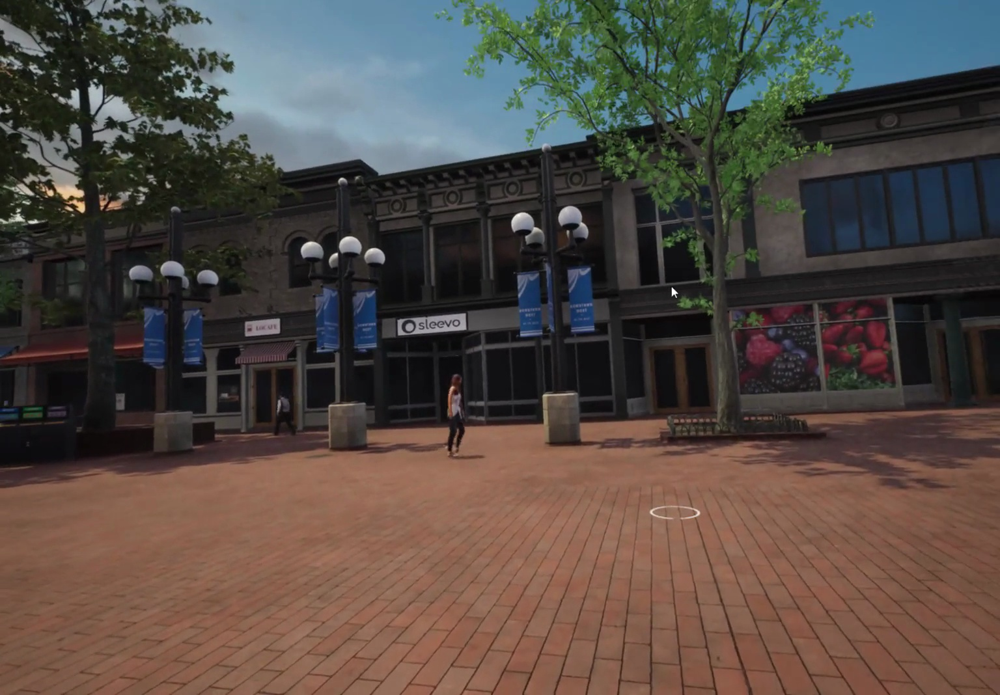
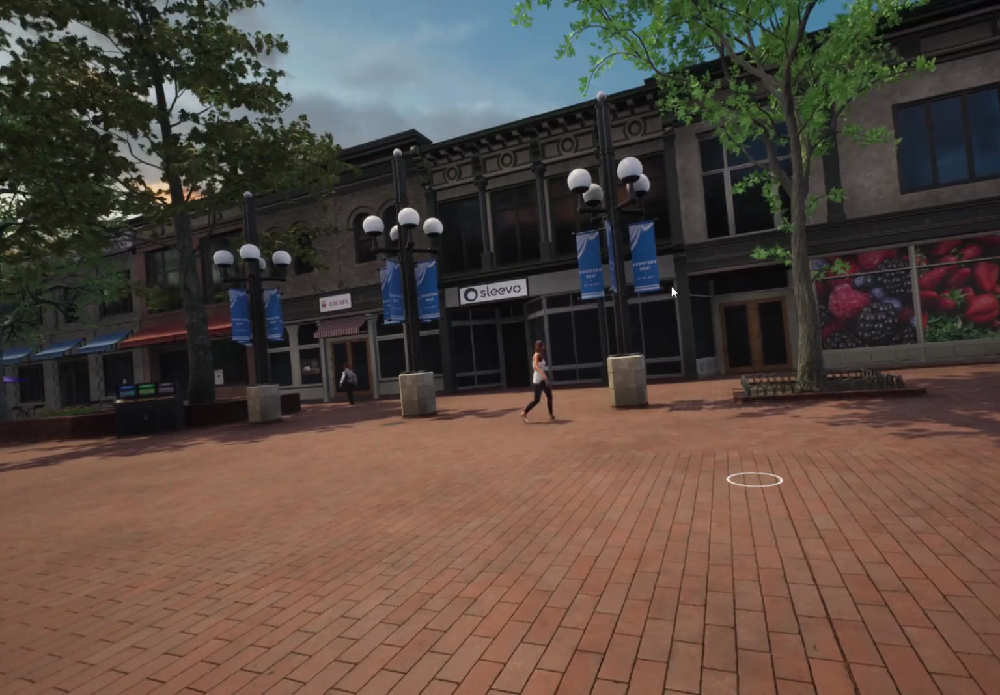
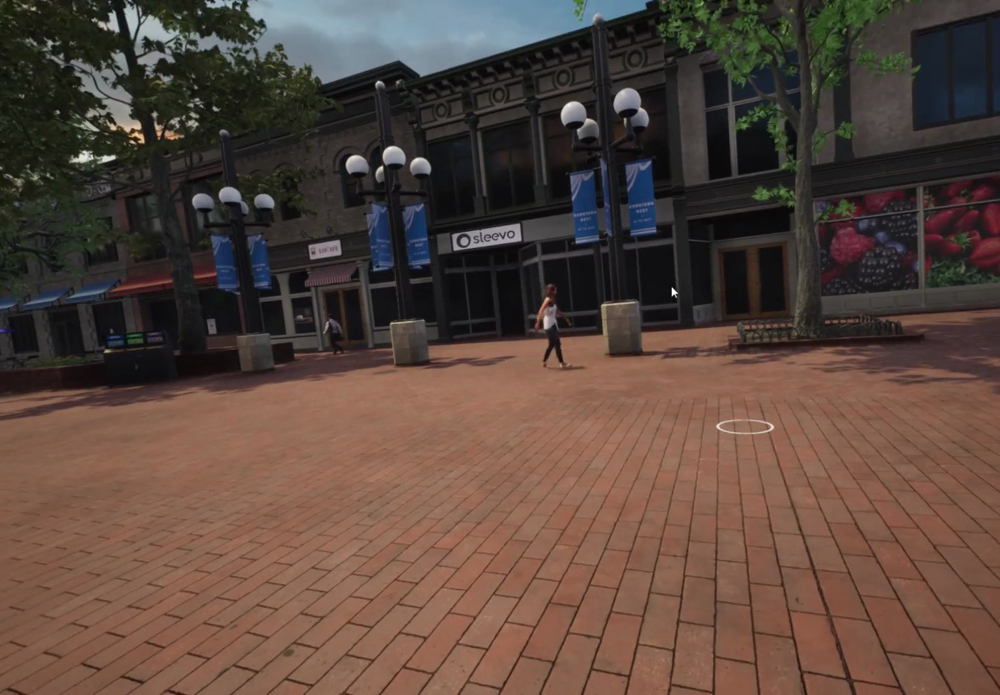
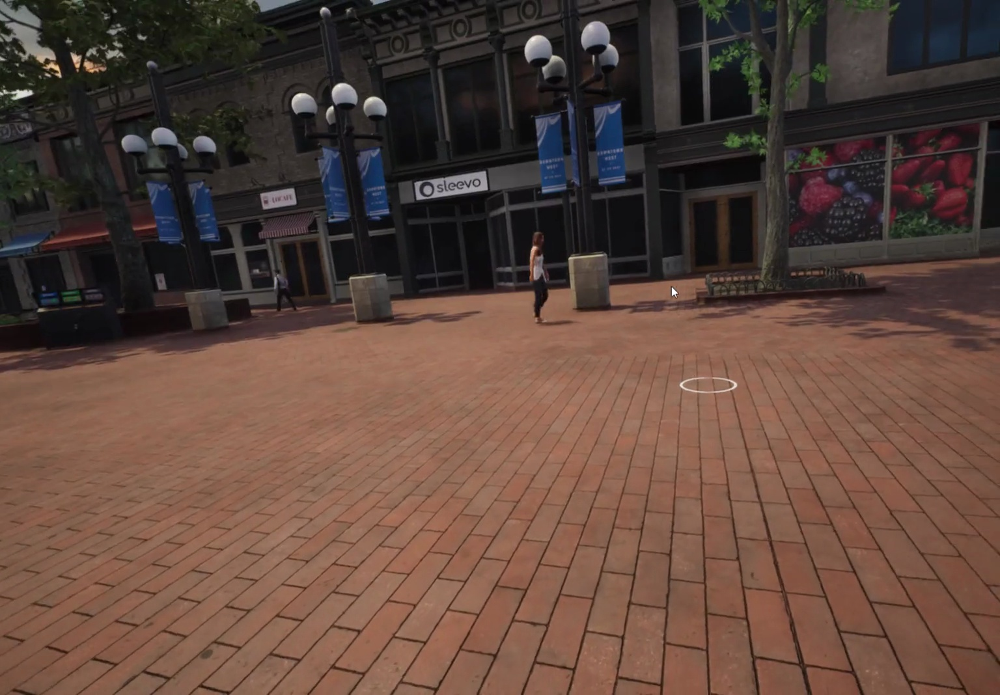
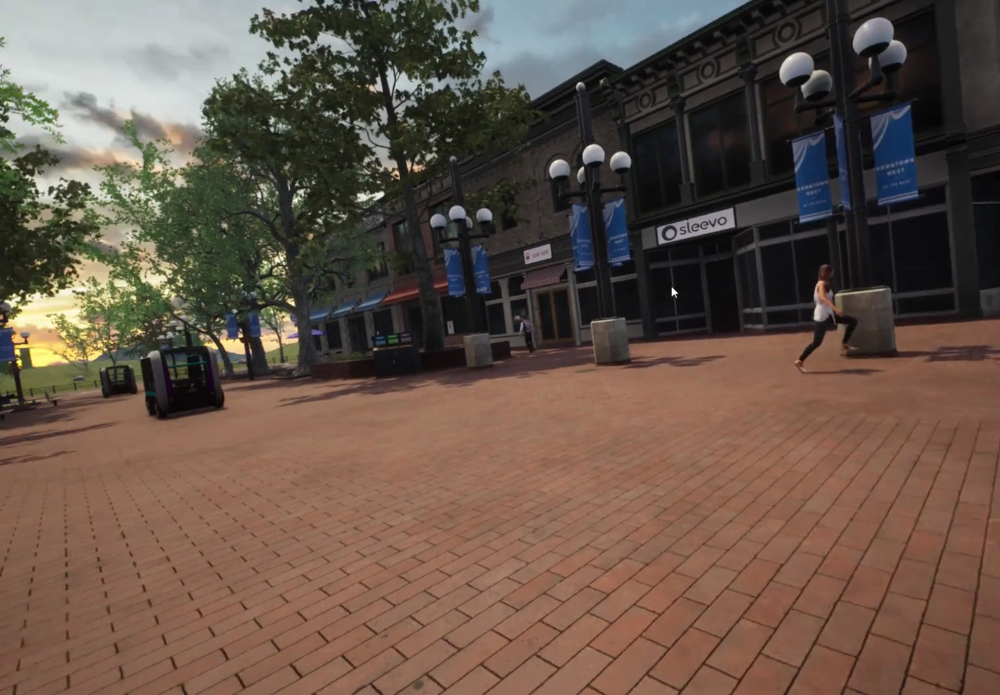
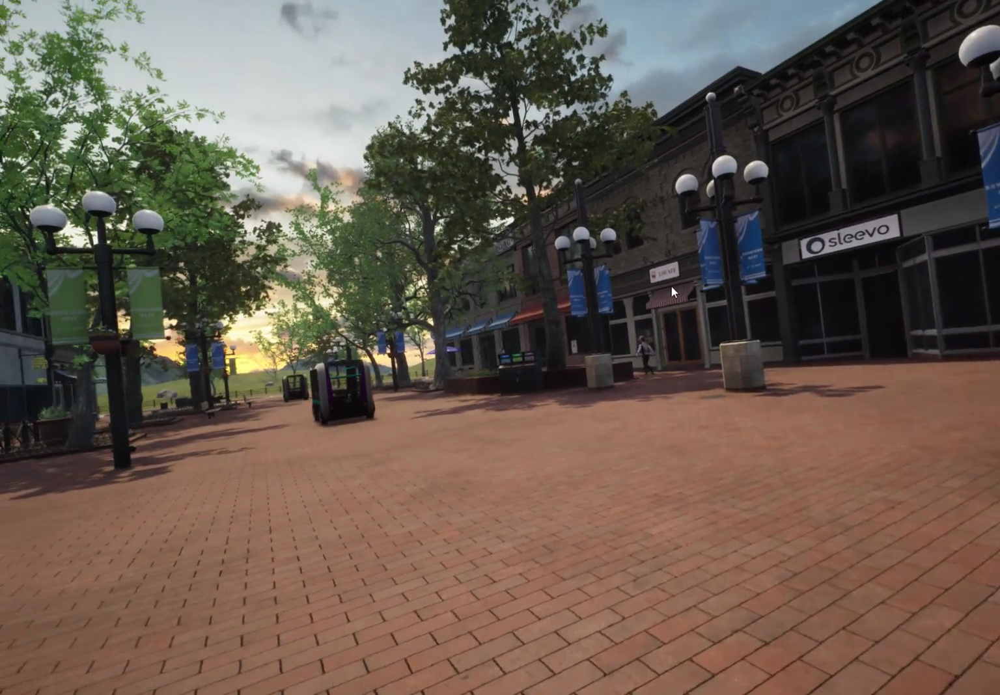
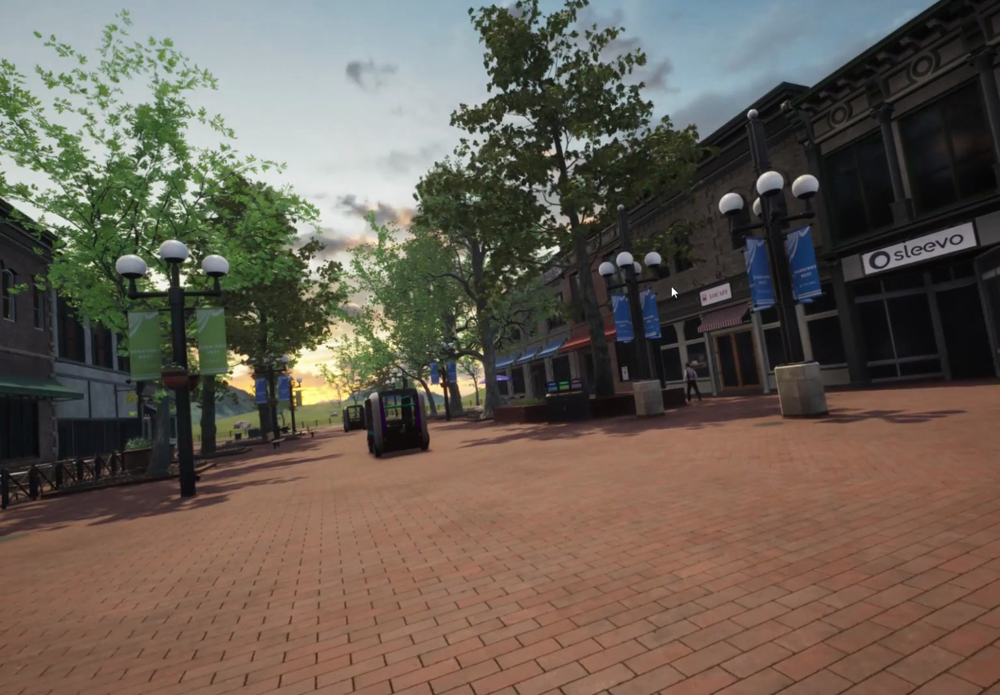
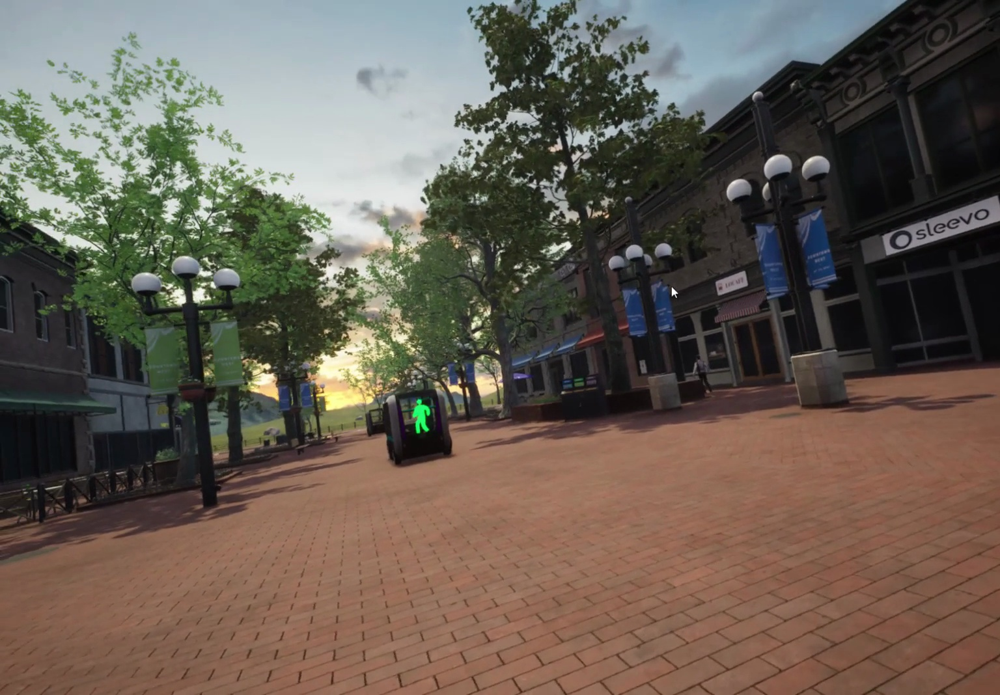
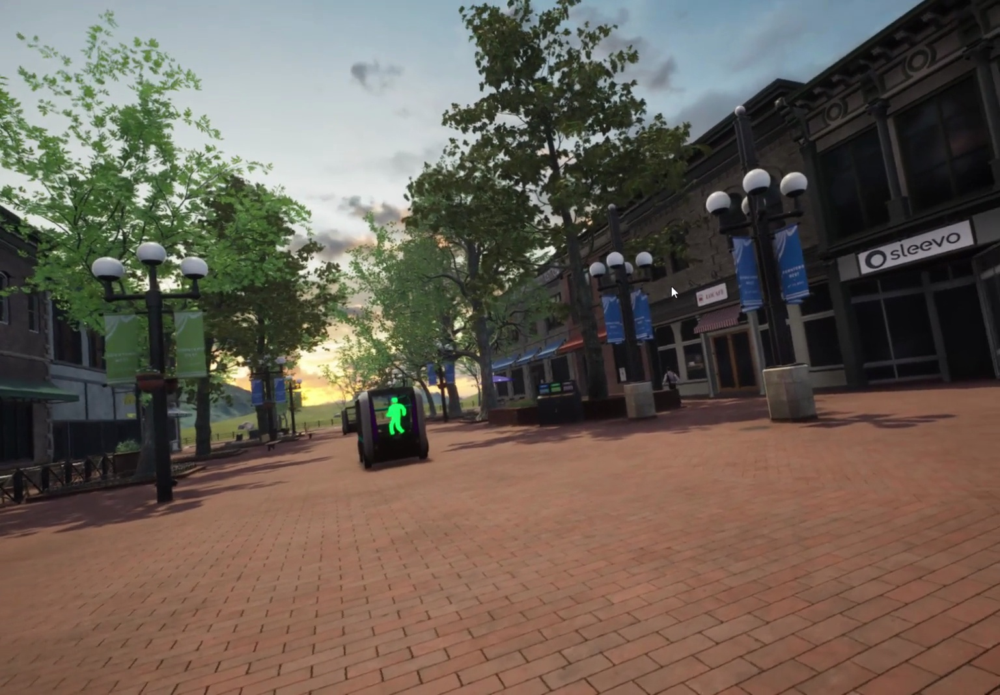

In [ ]:
content = [
    {
        "type": "input_text",
        "text": '''
Analyze the provided consecutive first-person video frames of a viewer interacting with automated pods in a shared space.

0. Coordinate system
The reference system is defined relative to the automated pod's movement:
X-Axis: Set along the pod's moving direction (horizontal movement). Positive X: same as the pod's travel direction (toward the viewer in these frames).
Y-Axis: Set perpendicular to the pod's path (lateral movement). Positive Y: leftward in the image; rightward motion is negative Y. 

1. Context:
Goal: The white circle on the ground indicates the viewer's target position, which is on the other side of the pod. 
Images: The frames represent the current head/eye-level view based on the viewer's head direction.
Red pedestrian signal on the pod: indicates that the pod will not yield to the pedestrian.
Green pedestrian signal on the pod: indicates that the pod will yield to the pedestrian.
Both signals are suggestive of the pod's intent, and the viewer doesn't need to follow it.

2. Dynamic and Spatial Inference
Based on visual evidence (changes in perspective, size, and relative positions) across consecutive frames, infer the following kinematic and spatial data:
Viewer Position: Infer the viewer's current position relative to the pods and the goal (e.g., nearing an intersection, adjacent to a pod, mid-path).
Viewer Movement Type: Is the viewer moving significantly along the X-axis (horizontal movement, positive or negative direction)? Is the viewer moving significantly along the Y-axis (lateral movement, positive or negative direction)?
Viewer Status: Is the viewer speeding up, maintaining speed, or decelerating (change in X and Y velocity)?
Pod Status: Is the automated pod accelerating, maintaining speed, or decelerating?
Estimate the distance between the viewer and pods, both lateral and horizontal. 

3. Interaction, Safety, and Intent Analysis
Gaze and Attention: What specific objects or areas (pods, ground, goal, periphery) could the viewer pay attention to?
Safety & Communication: Provide insights into potential safety concerns (e.g., proximity, sight lines, potential collision points) or observable communication signals (e.g., a deliberate head turn, a pod's change in speed/direction, or light signals).
Crossing Intent: Based on all the analyses, what do you think will be the action of the viewer in the next 1.5 seconds? Accelerate to the right, Maintain current speed, Decelerate to the right, Stop, Move backward. Provide a clear answer with supporting rationales and a confidence score.
''',}
]
content.extend(image_messages)

content

In [164]:
%%time
response = client.responses.create(
    model="gpt-5",
    input=[
        {
            "role": "user",
            "content": content,
        }
    ]
)

CPU times: user 28.2 ms, sys: 39.9 ms, total: 68.2 ms
Wall time: 1min 2s


In [165]:
print(response.output_text)

0) Frame of reference (given)
- +X: along the pod’s travel direction (toward the viewer).
- +Y: to the viewer’s left. Rightward motion is −Y.

1) Context understanding
- Goal (white circle) lies across the pod’s path; the viewer must cross the pod lane to reach it.
- By −1.0 s the viewer has turned head/torso to the left to assess two approaching automated pods. At −0.25–0.0 s the lead pod shows a green pedestrian signal (yield).

2) Dynamic and spatial inference

Viewer position
- In the plaza, near the edge of the pod lane; goal is on the far side of that lane.
- Relative to the lead pod at 0.0 s: ahead-right of it.

Viewer movement type
- Longitudinal (X): minimal change from −1.0 to 0.0 s (≈0 or slight +X drift). The view change is mostly head yaw, not translation.
- Lateral (Y): little net displacement; the viewer had been trending slightly rightward earlier, then paused to look left.

Viewer status
- Decelerating to (near) a stop from −1.0 s onward while checking pods.

Pod statu

In [166]:
# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

file = 'P22S1'
frame_number = 105
images = [
    {"path": f"../data/videoframes/{file}/frame_000{frame_number:03d}.jpg", "time elapsed": "-2.0"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 9:03d}.jpg", "time elapsed": "-1.75"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 18:03d}.jpg", "time elapsed": "-1.5"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 27:03d}.jpg", "time elapsed": "-1.25"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 36:03d}.jpg", "time elapsed": "-1.0"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 45:03d}.jpg", "time elapsed": "-0.75"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 54:03d}.jpg", "time elapsed": "-0.5"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 63:03d}.jpg", "time elapsed": "-0.25"},
    {"path": f"../data/videoframes/{file}/frame_000{frame_number + 72:03d}.jpg", "time elapsed": "0.0"},
]

image_messages = []
for img in images:
    image_messages.append({"type": "input_text", "text": f"Image at {img['time elapsed']} seconds."})
    image_messages.append({"type": "input_image", "image_url": f"data:image/jpeg;base64,{encode_image(img['path'])}", "detail": "low"})

In [167]:
print(f'{frame_number/36:.2f}, {(frame_number+72)/36:.2f}')

2.92, 4.92


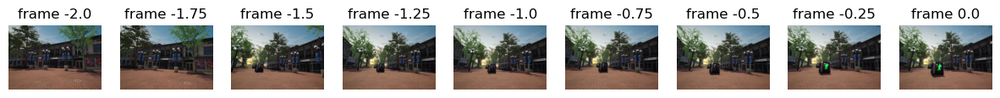

In [168]:
fig, axs = plt.subplots(1, len(images), figsize=(15, 5))
for ax, imgfile in zip(axs, images):
    # read image
    img_data = cv2.imread(imgfile['path'])
    img_data = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)
    ax.imshow(img_data)
    ax.set_title(f'frame {imgfile["time elapsed"]}')
    ax.axis('off')
plt.show()

[{'type': 'input_text', 'text': 'Image at -2.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.75 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.25 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -1.0 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.75 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.5 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_text', 'text': 'Image at -0.25 seconds.'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'i
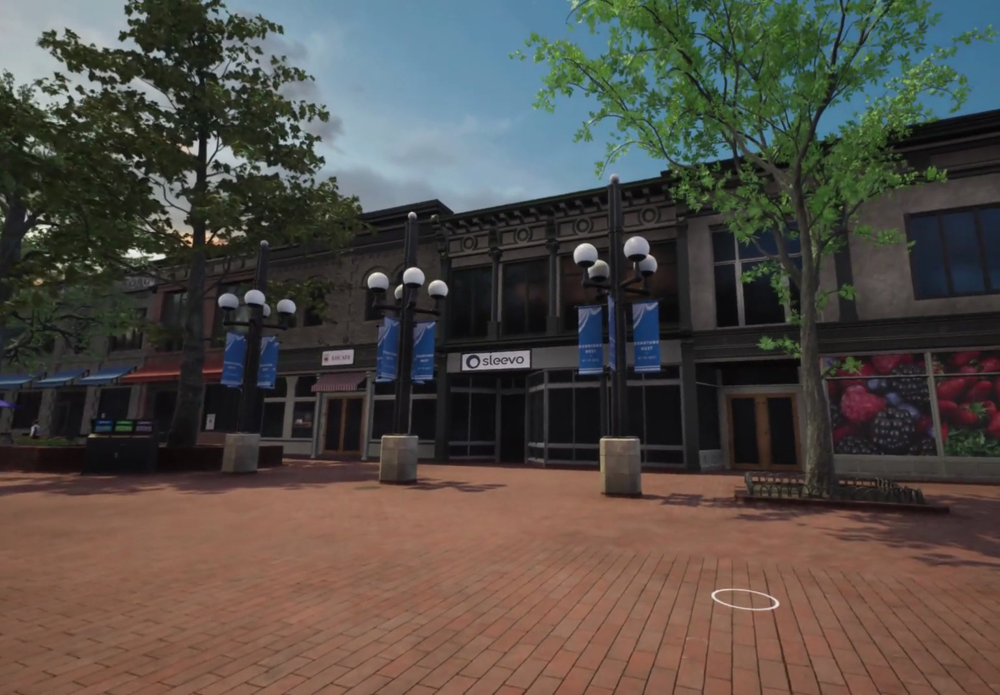
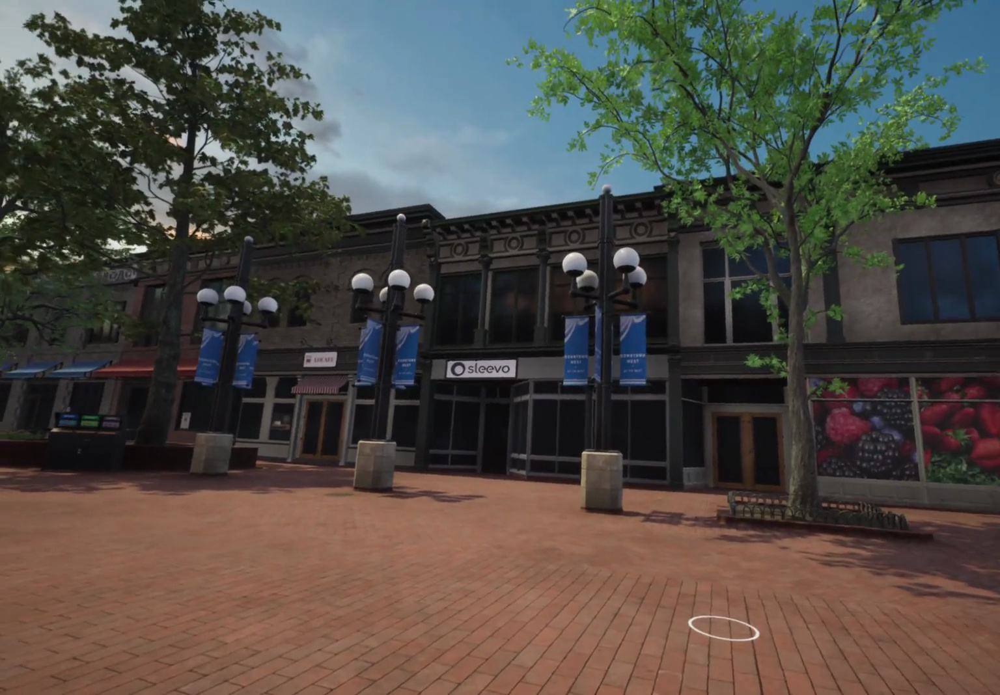
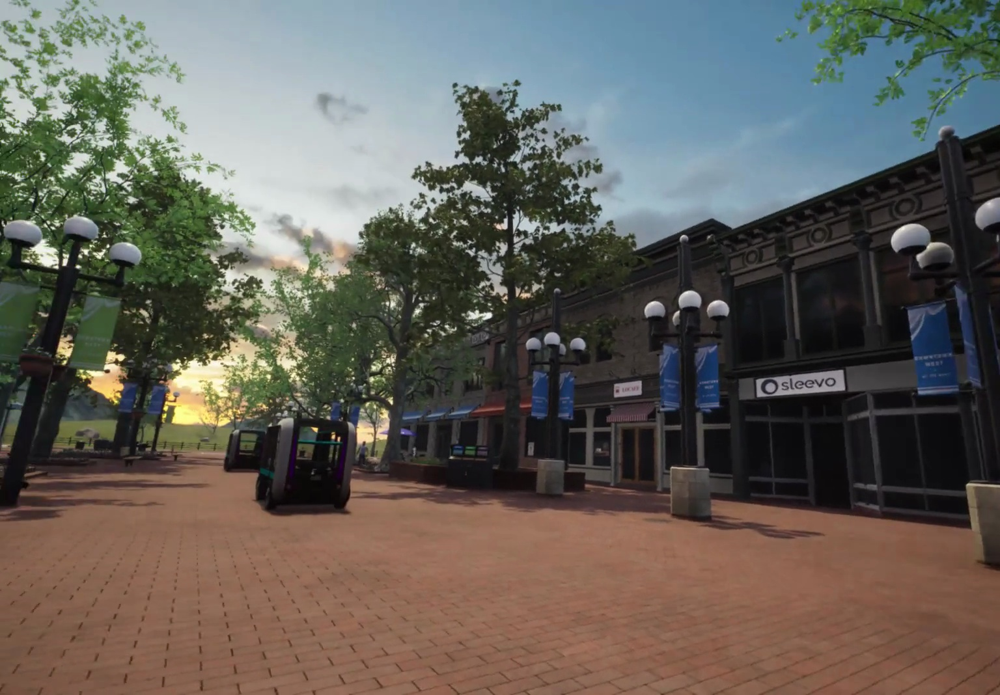
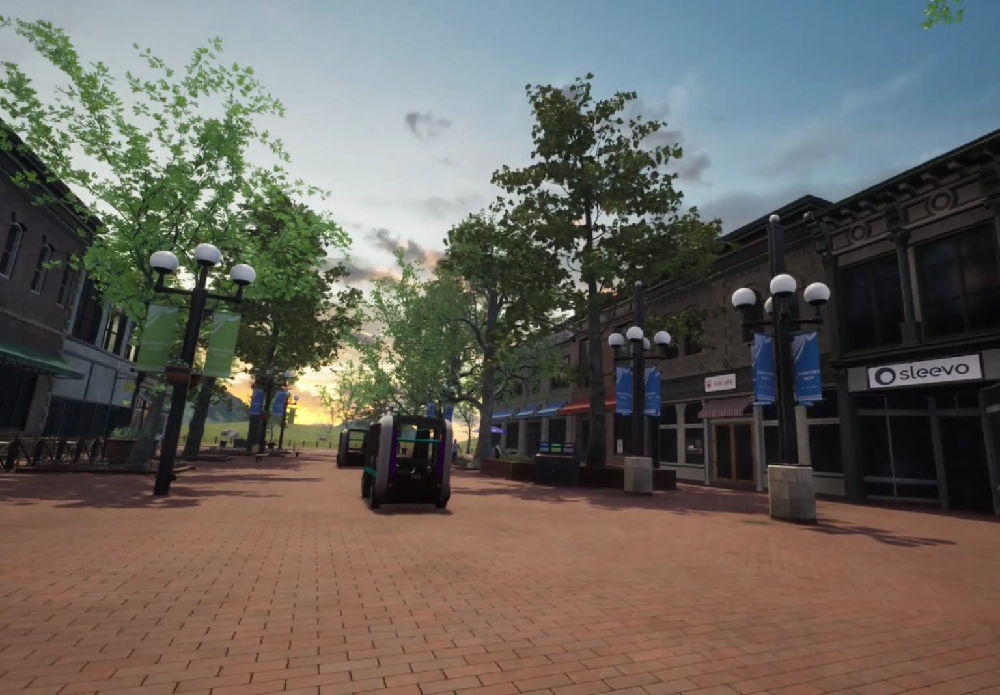
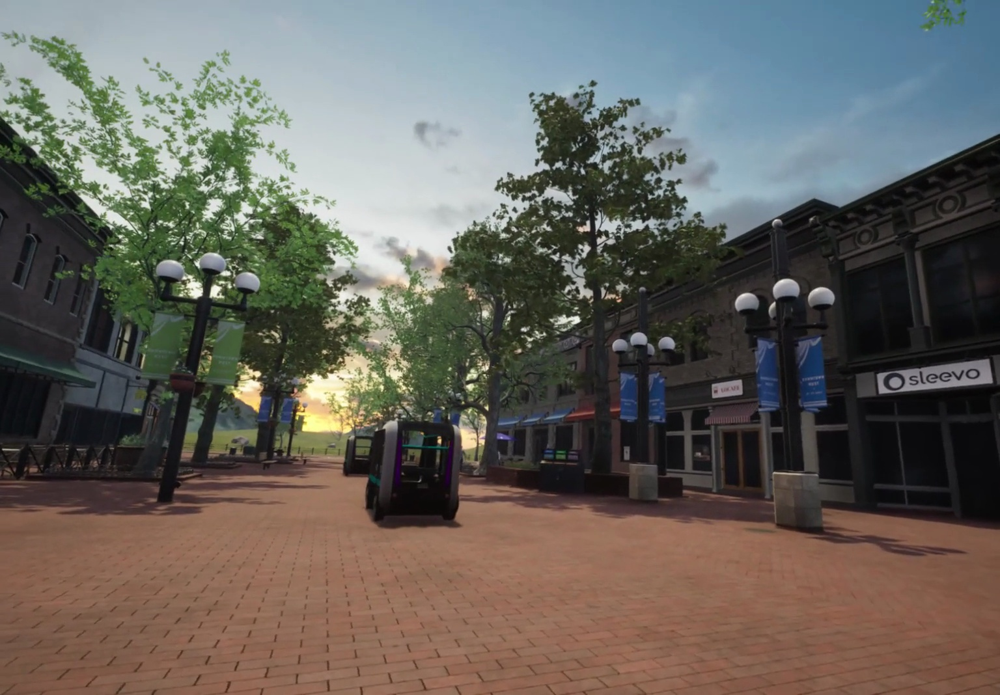
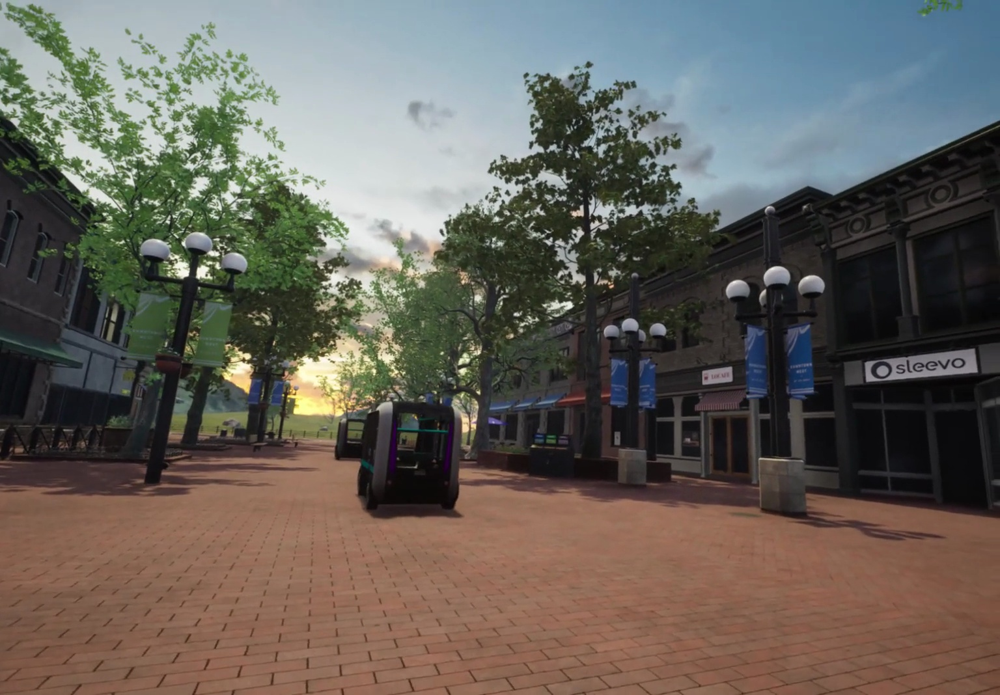
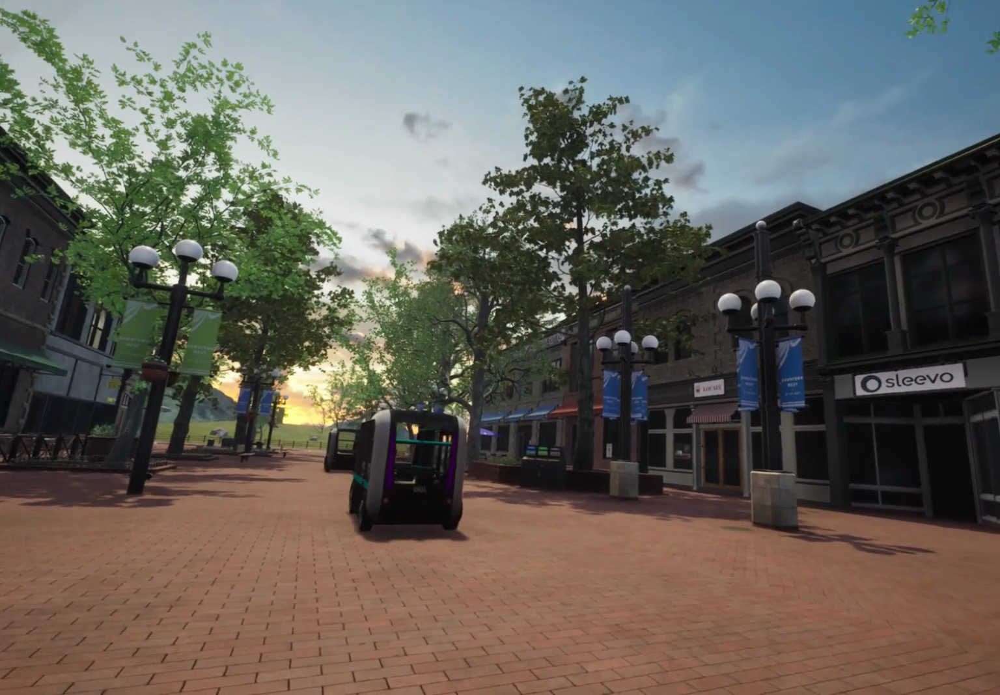
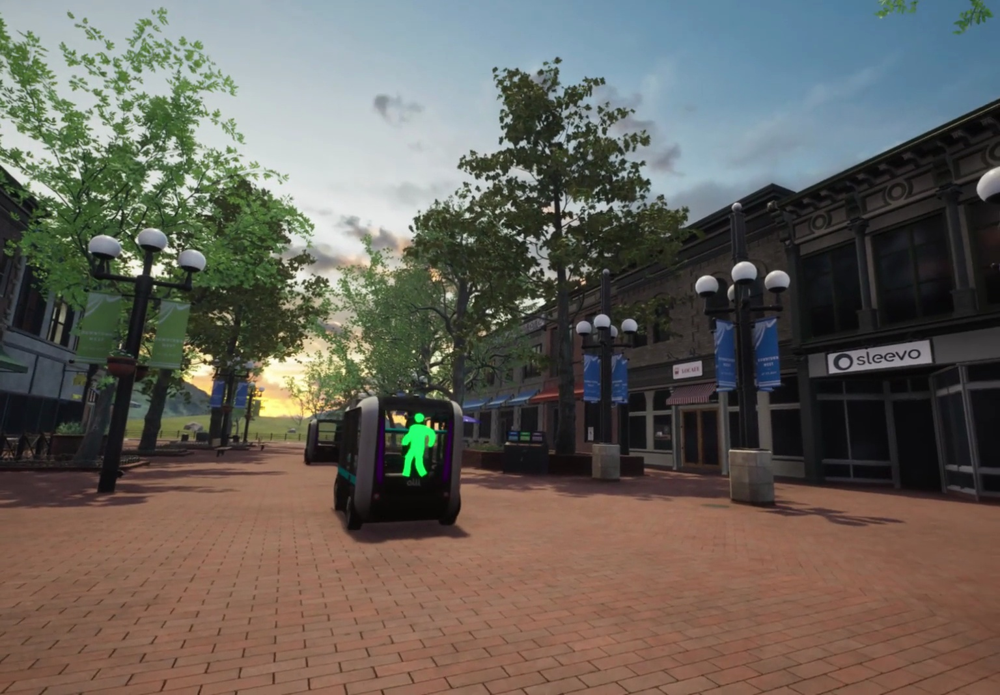
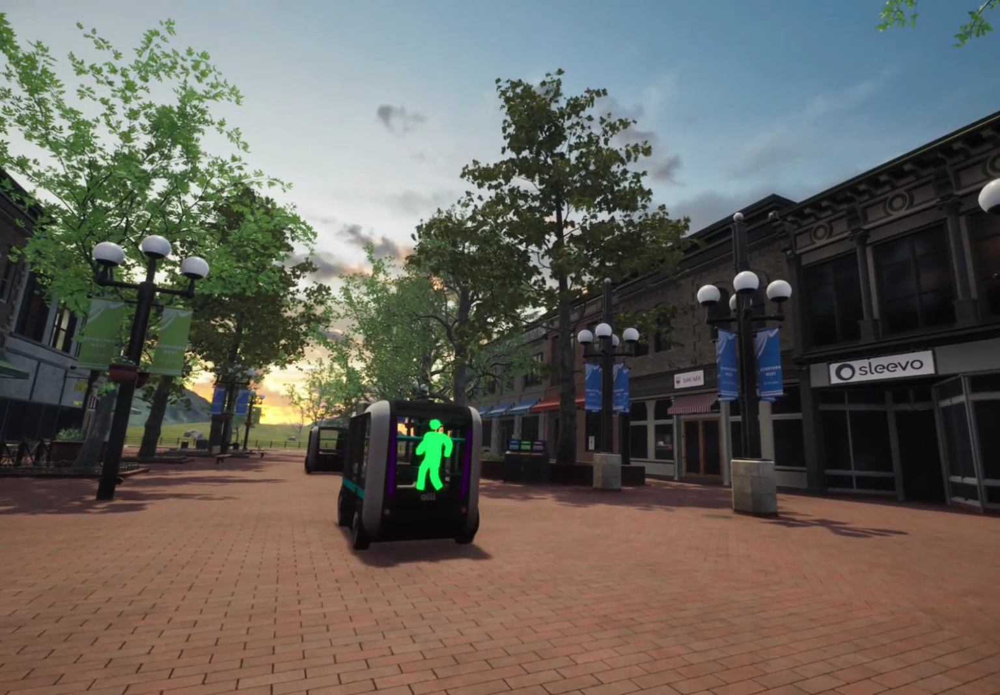

In [169]:
image_messages

[{'type': 'input_text',
  'text': "\nAnalyze the provided consecutive first-person video frames of a viewer interacting with automated pods in a shared space.\n\n0. Coordinate system\nThe reference system is defined relative to the automated pod's movement:\nX-Axis: Set along the pod's moving direction (horizontal movement). Positive X: same as the pod's travel direction (toward the viewer in these frames).\nY-Axis: Set perpendicular to the pod's path (lateral movement). Positive Y: leftward in the image; rightward motion is negative Y. \n\n1. Context:\nGoal: The white circle on the ground indicates the viewer's target position, which is on the other side of the pod. \nImages: The frames represent the current head/eye-level view based on the viewer's head direction.\nRed pedestrian signal on the pod: indicates that the pod will not yield to the pedestrian.\nGreen pedestrian signal on the pod: indicates that the pod will yield to the pedestrian.\nBoth signals are suggestive of the pod's
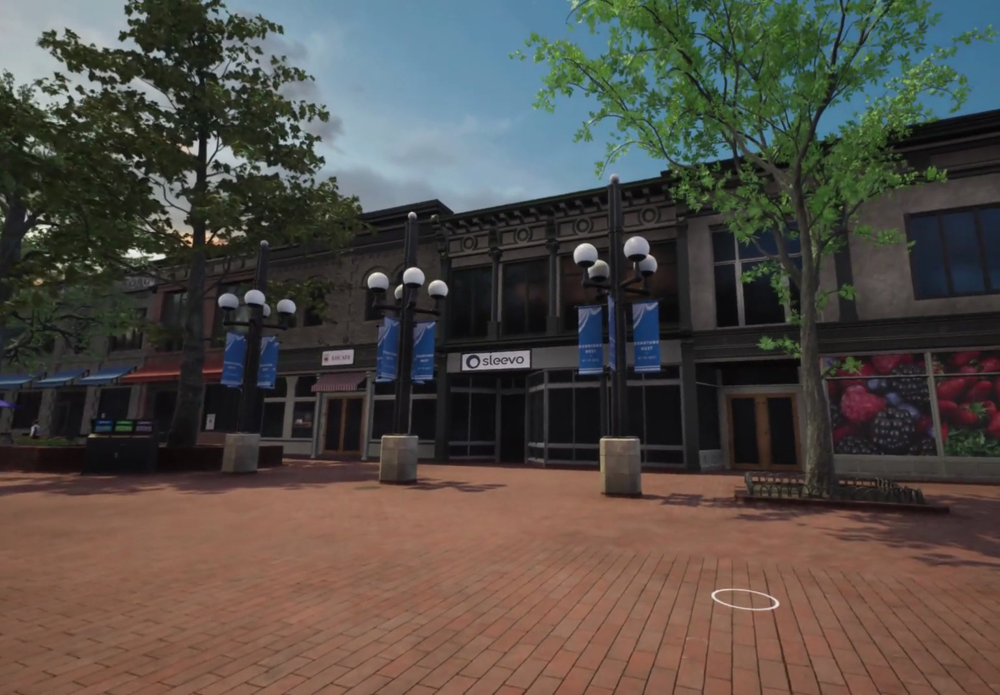
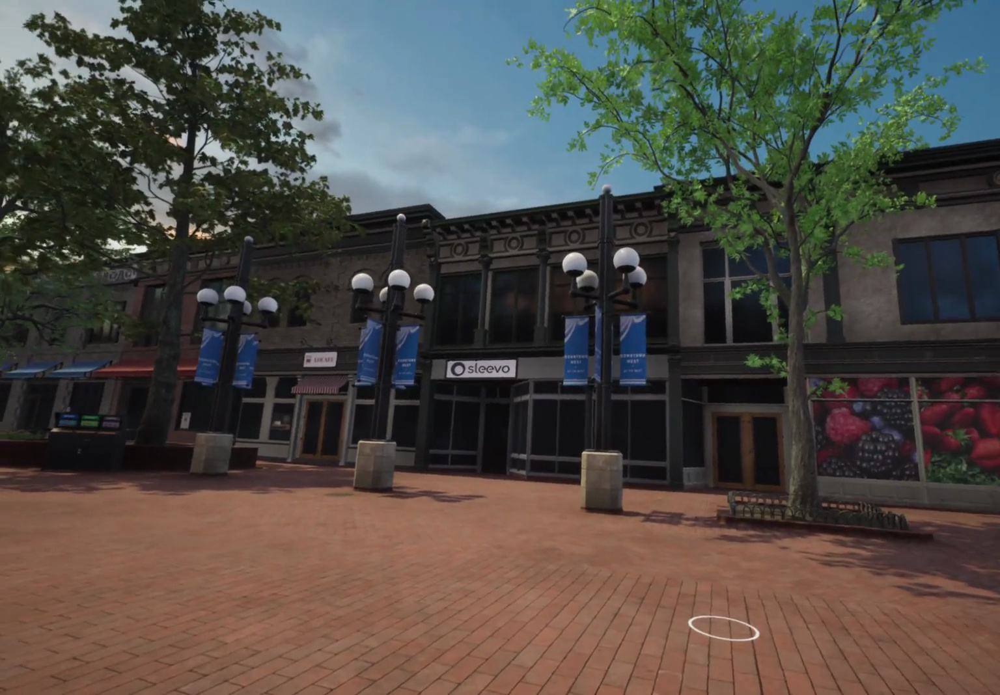
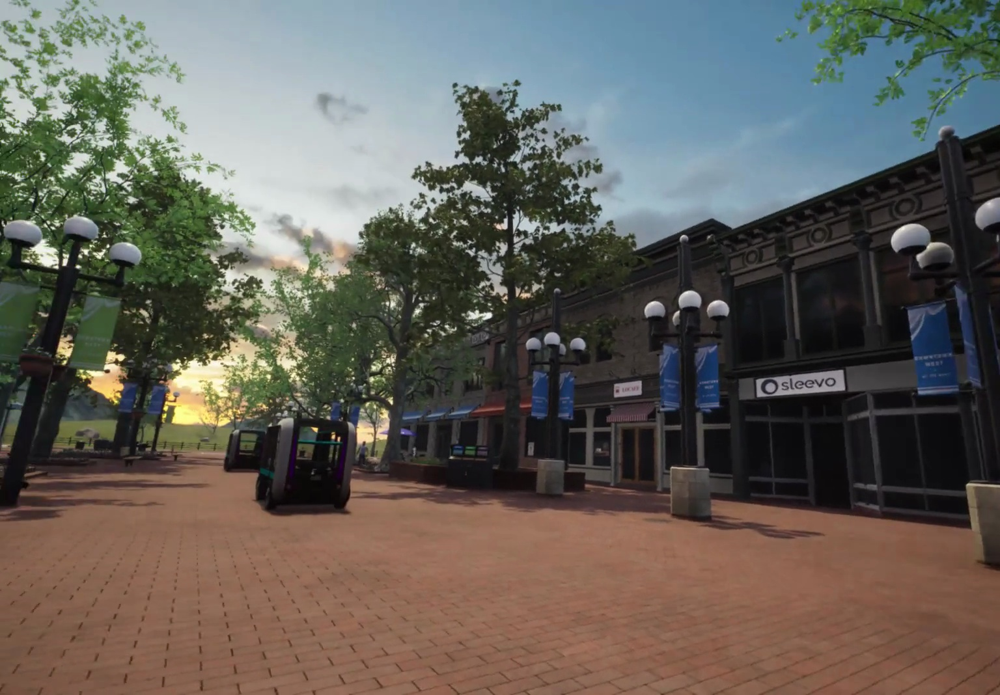
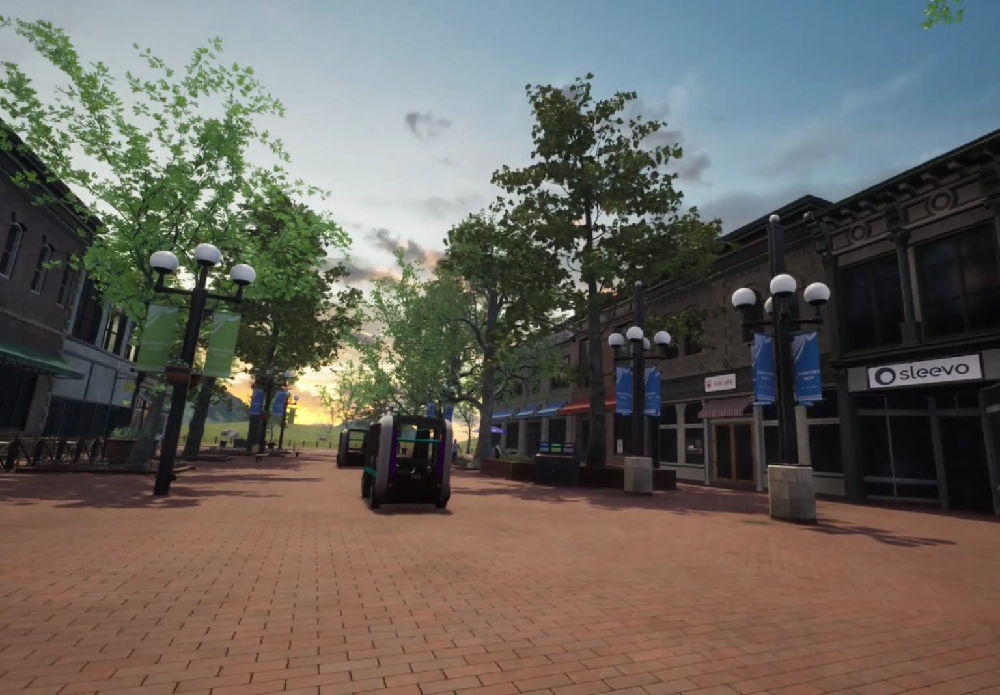
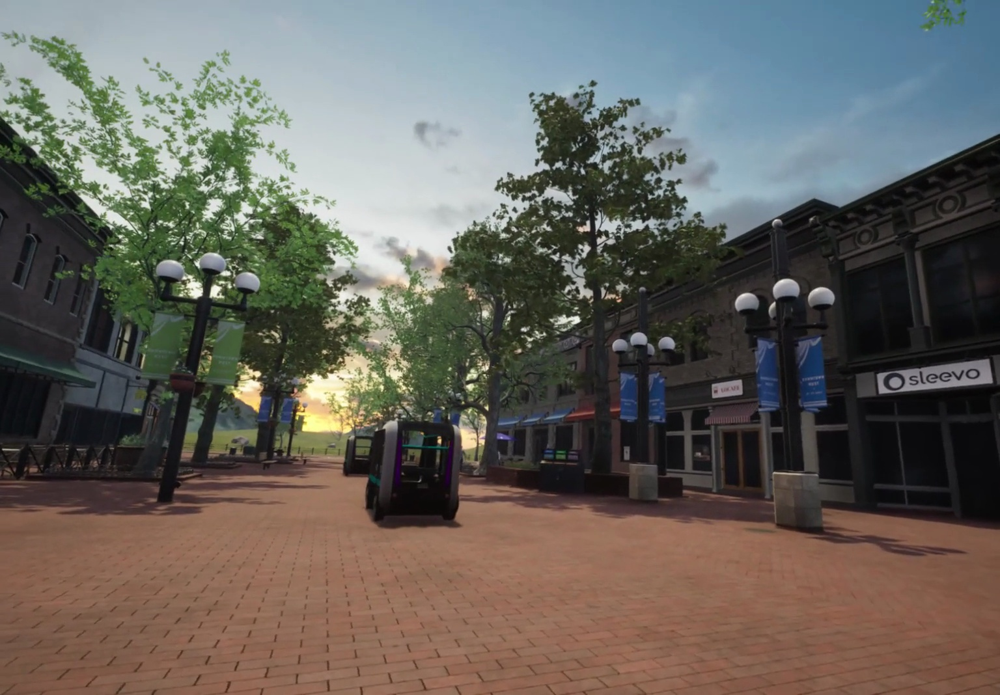
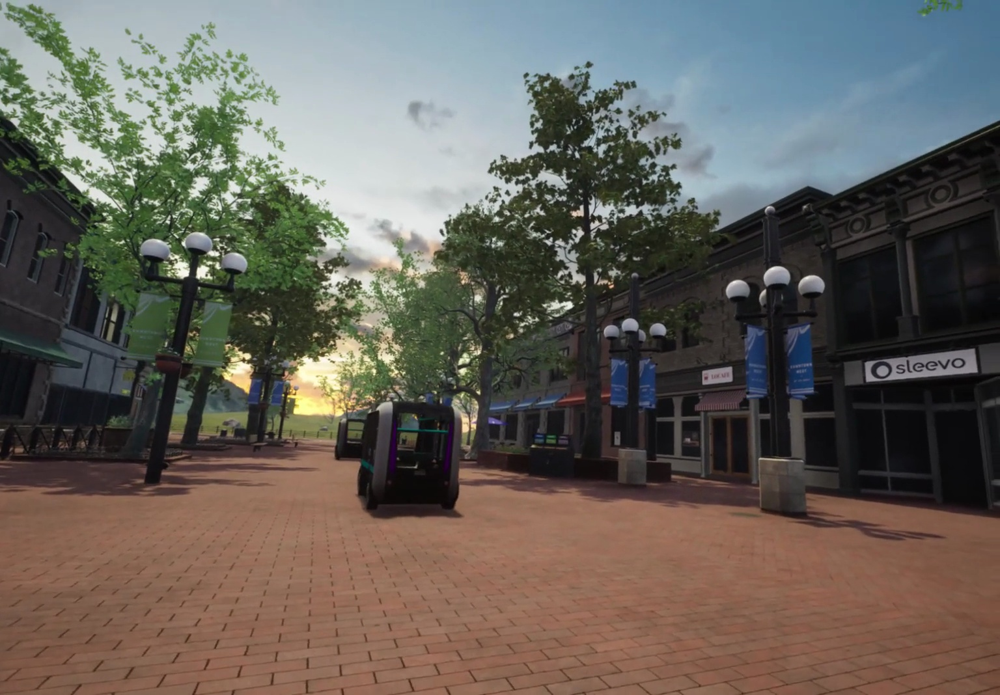
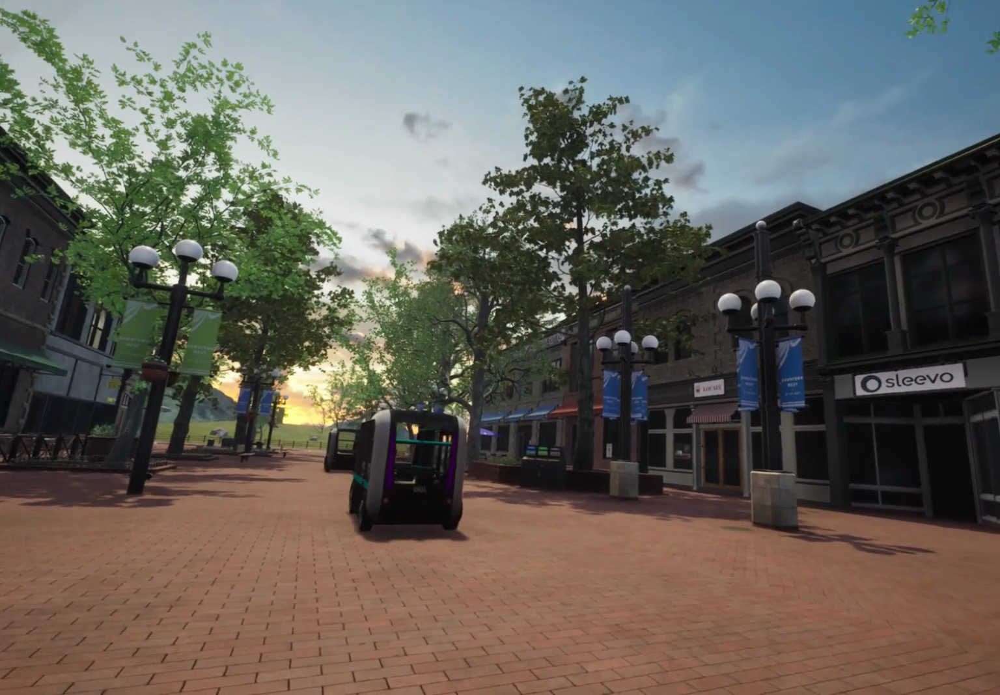
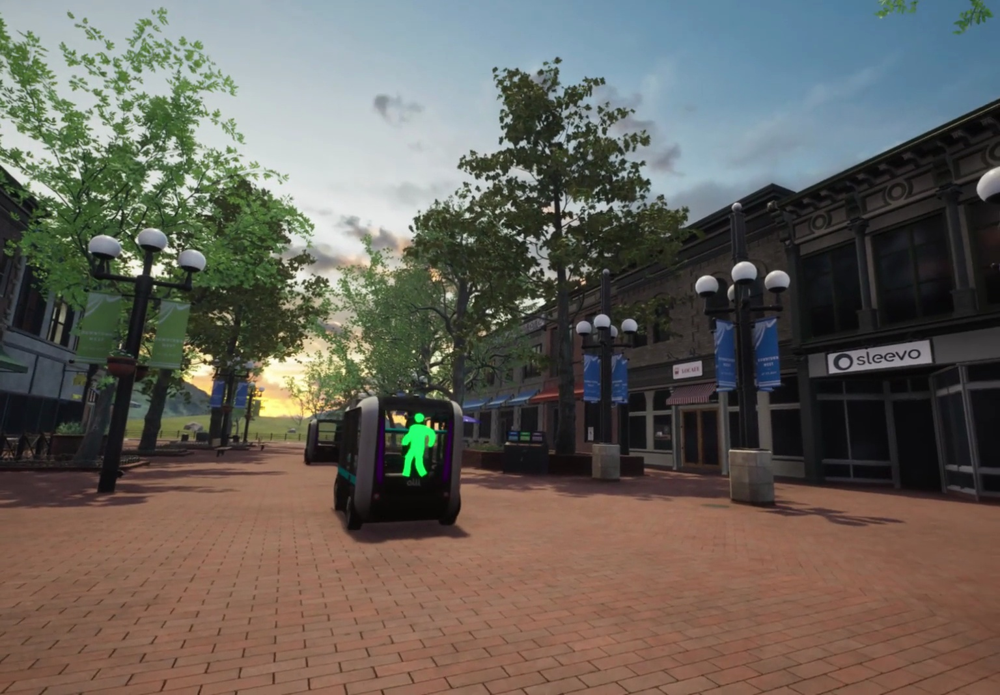
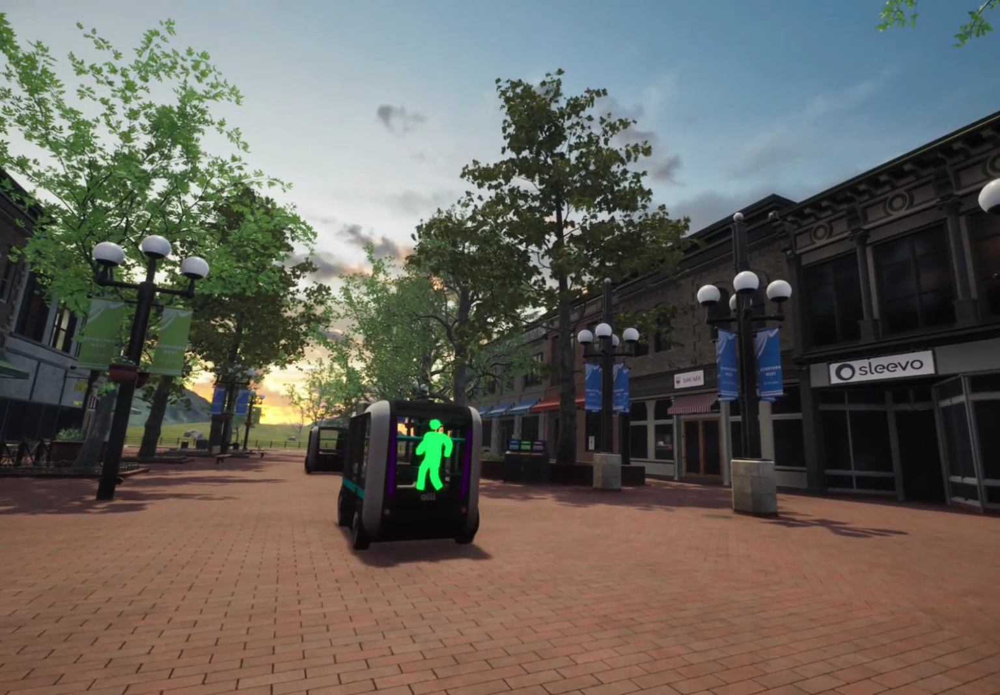

In [170]:
content = [
    {
        "type": "input_text",
        "text": '''
Analyze the provided consecutive first-person video frames of a viewer interacting with automated pods in a shared space.

0. Coordinate system
The reference system is defined relative to the automated pod's movement:
X-Axis: Set along the pod's moving direction (horizontal movement). Positive X: same as the pod's travel direction (toward the viewer in these frames).
Y-Axis: Set perpendicular to the pod's path (lateral movement). Positive Y: leftward in the image; rightward motion is negative Y. 

1. Context:
Goal: The white circle on the ground indicates the viewer's target position, which is on the other side of the pod. 
Images: The frames represent the current head/eye-level view based on the viewer's head direction.
Red pedestrian signal on the pod: indicates that the pod will not yield to the pedestrian.
Green pedestrian signal on the pod: indicates that the pod will yield to the pedestrian.
Both signals are suggestive of the pod's intent, and the viewer doesn't need to follow it.
Viewer's characteristics: female, 23 years old, chinese. The score of familiarity and experience with automated pods is 2/5. Trust towards automation score is 5.83/7. Score of violation behavior in daily life (e.g., cross the street even though the pedestrian light is red, cross diagonally to save time) is 3.75/6. Score of lapse behavior (e.g., realize that I have crossed several streets and intersections without paying attention to traffic, cross without looking because I am talking with someone) is 2.5/6. Score of positive behavior (e.g., thank a driver who stops to let me cross; let a car go by, even if I have the right-of-way, if there is no other vehicle behind it) is 5.33/6. 

2. Dynamic and Spatial Inference
Based on visual evidence (changes in perspective, size, and relative positions) across consecutive frames, infer the following kinematic and spatial data:
Viewer Position: Infer the viewer's current position relative to the pods and the goal (e.g., nearing an intersection, adjacent to a pod, mid-path).
Viewer Movement Type: Is the viewer moving significantly along the X-axis (horizontal movement, positive or negative direction)? Is the viewer moving significantly along the Y-axis (lateral movement, positive or negative direction)?
Viewer Status: Is the viewer speeding up, maintaining speed, or decelerating (change in X and Y velocity)?
Pod Status: Is the automated pod accelerating, maintaining speed, or decelerating?
Estimate the distance between the viewer and pods, both lateral and horizontal. 

3. Interaction, Safety, and Intent Analysis
Safety & Communication: Provide insights into potential safety concerns (e.g., proximity, sight lines, potential collision points) or observable communication signals (e.g., a deliberate head turn, a pod's change in speed/direction, or light signals).
Crossing Intent: Based on all the analyses, what do you think will be the action of the viewer in the next 1.5 seconds? Accelerate to the right, Maintain current speed, Decelerate to the right, Stop, Move backward. Provide a clear answer with supporting rationales and a confidence score.
''',}
]
content.extend(image_messages)

content

In [171]:
%%time
response = client.responses.create(
    model="gpt-5",
    input=[
        {
            "role": "user",
            "content": content,
        }
    ]
)

CPU times: user 28.2 ms, sys: 24.3 ms, total: 52.5 ms
Wall time: 1min 4s


In [172]:
print(response.output_text)

1) Frame-to-frame kinematic/spatial inference (X = pod travel toward viewer; Y = left/right in image)

- Viewer position
  - Starts in an open plaza, facing the pod lane. Goal circle was on the right side of view (other side of the approaching pod).
  - By 0.0 s the nearest pod is centered-left ~5–6 m away on the pod lane; viewer stands near the lane’s right edge.

- Viewer movement type
  - X (along pod path): negligible translation; no clear forward/back motion.
  - Y (lateral): minimal translation; mostly a head turn to the left to watch the pods. Any actual body motion is very small.

- Viewer status (speed change)
  - Essentially maintaining near‑zero speed; no clear acceleration or deceleration in X or Y.

- Pod status
  - Lead pod moves in +X toward the viewer from far range, then displays a green pedestrian icon by −0.25 s and visibly slows. Between −0.25 s and 0.0 s its apparent size changes little ⇒ decelerating to a near stop/yield.
  - A second pod follows behind at larger 

## QWEN3-VL

In [1]:
import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

In [ ]:
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

# default: Load the model on the available device(s)
model = Qwen3VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen3-VL-8B-Instruct", dtype="auto", device_map="auto"
)

# We recommend enabling flash_attention_2 for better acceleration and memory saving, especially in multi-image and video scenarios.
# model = Qwen3VLForConditionalGeneration.from_pretrained(
#     "Qwen/Qwen3-VL-8B-Instruct",
#     dtype=torch.bfloat16,
#     attn_implementation="flash_attention_2",
#     device_map="auto",
# )

processor = AutoProcessor.from_pretrained("Qwen/Qwen3-VL-8B-Instruct")

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": "https://qianwen-res.oss-cn-beijing.aliyuncs.com/Qwen-VL/assets/demo.jpeg",
            },
            {"type": "text", "text": "Describe this image."},
        ],
    }
]

# Preparation for inference
inputs = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
)
inputs = inputs.to(model.device)

# Inference: Generation of the output
generated_ids = model.generate(**inputs, max_new_tokens=128)
generated_ids_trimmed = [
    out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
]
output_text = processor.batch_decode(
    generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
)
print(output_text)


Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

model-00002-of-00004.safetensors:   0%|          | 0.00/4.92G [00:00<?, ?B/s]

model-00004-of-00004.safetensors:   0%|          | 0.00/2.72G [00:00<?, ?B/s]

model-00001-of-00004.safetensors:   0%|          | 0.00/4.90G [00:00<?, ?B/s]

model-00003-of-00004.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

In [1]:
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

# default: Load the model on the available device(s)
model = Qwen3VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen3-VL-8B-Instruct", dtype="auto", device_map="auto"
)

# We recommend enabling flash_attention_2 for better acceleration and memory saving, especially in multi-image and video scenarios.
# model = Qwen3VLForConditionalGeneration.from_pretrained(
#     "Qwen/Qwen3-VL-8B-Instruct",
#     dtype=torch.bfloat16,
#     attn_implementation="flash_attention_2",
#     device_map="auto",
# )

processor = AutoProcessor.from_pretrained("Qwen/Qwen3-VL-8B-Instruct")

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "text",
                "text": "These are frames sampled from a first-person video of an person interacting with automated vehicles in shared spaces. \
                        Observe what the person is paying attention to. Analyze the images and provide insights about the interactions, behaviors, and any notable observations regarding safety, communication, and navigation. \
                        Does this person intend to cross in front of the AV in the next 1.5 seconds?",
            },
            {"type": "text", "text": "Image at frame 0.0 seconds."},
            {
                "type": "image",
                "image": "../data/frames/P4-2/frame_000460.jpg",
            },
            {"type": "text", "text": "Image at frame 0.5 seconds."},
            {
                "type": "image",
                "image": "../data/frames/P4-2/frame_000478.jpg",
            },
            {"type": "text", "text": "Image at frame 1.0 seconds."},
            {
                "type": "image",
                "image": "../data/frames/P4-2/frame_000496.jpg",
            },
            {"type": "text", "text": "Image at frame 1.5 seconds."},
            {
                "type": "image",
                "image": "../data/frames/P4-2/frame_000514.jpg",
            },
            {"type": "text", "text": "Image at frame 2.0 seconds."},
            {
                "type": "image",
                "image": "../data/frames/P4-2/frame_000532.jpg",
            },
        ],
    }
]

# Preparation for inference
inputs = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
)
inputs = inputs.to(model.device)

# Inference: Generation of the output
generated_ids = model.generate(**inputs, max_new_tokens=128)
generated_ids_trimmed = [
    out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
]
output_text = processor.batch_decode(
    generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
)
print(output_text)


Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

LookupError: <ContextVar name='shell_parent' at 0x108ecf6f0>

In [3]:
import sys
print(sys.executable)

/Users/danli/anaconda3/envs/work3/bin/python


In [4]:
import sys
for p in sys.path:
    print(p)

/Users/danli/anaconda3/envs/work3/lib/python312.zip
/Users/danli/anaconda3/envs/work3/lib/python3.12
/Users/danli/anaconda3/envs/work3/lib/python3.12/lib-dynload

/Users/danli/anaconda3/envs/work3/lib/python3.12/site-packages
/var/folders/vk/wc7mk0p13r31xnm_nqv76gnh0000gp/T/tmpx7mkf0rv


In [5]:
import torch
import ipywidgets as widgets

print(torch.__version__)
widgets.IntSlider()

2.7.1


IntSlider(value=0)

In [6]:
import sys; print(sys.executable); print(sys.version); import torch; print(torch.__file__)


/Users/danli/anaconda3/envs/work3/bin/python
3.12.12 | packaged by conda-forge | (main, Oct 13 2025, 14:47:45) [Clang 19.1.7 ]
/Users/danli/anaconda3/envs/work3/lib/python3.12/site-packages/torch/__init__.py
